# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import pickle
import os
import glob

## df

In [2]:
df = pd.read_parquet(r'bert_trainset_squared_25.gzip')
print(df.shape)
df_uniques = [val for val in df['position_state'].unique()]
df['position_state_id'] = df.groupby('position_state').transform('ngroup')
print(len(df_uniques))
df.head(2)

(13134, 11)
947


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,864,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,863,1.021119,968.0,1


In [3]:
df[['position_state_id', 'position_state']].nunique()

position_state_id    947
position_state       947
dtype: int64

## apd

In [4]:
ziped_apd = True

In [5]:
if ziped_apd:
    apd = pd.read_parquet('apd_ziped.gzip')
else:
    apd = pd.read_parquet('apd_full.gzip')

In [6]:
print(apd.shape)
apd_uniques = [val for val in apd['position_state'].unique()]
print(len(apd_uniques))
apd.head(2)

(1002001, 5)
1057


,X,Y,pos,position_state,position_state_id
0,0.000,0.0,"[0.0, 0.0]",COQVSOAUMTASMTUPCRFN,225
1,0.001,0.0,"[0.001, 0.0]",COQVSOAUMTASMTUPCRFN,225


## ps_to_psid

In [7]:
if 'position_state_id' not in apd.columns:
    with open('ps_to_psid.pkl', 'rb') as file:
        ps_to_psid = pickle.load(file)

In [8]:
if 'position_state_id' not in apd.columns:
    apd['position_state_id'] = [ps_to_psid[k] for k in apd['position_state']]

## cossim

In [9]:
coss = pd.read_csv("cosine_similarity_matrix_gpt.csv")
print(coss.shape)
coss.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.267234,0.499110,0.049191,0.056792,0.271156,0.285378,0.179301,0.425057,0.314681,...,0.138036,0.040739,-0.014937,0.086856,-0.245179,-0.184397,0.061178,-0.332574,0.244812,0.0
1,0.267234,1.000000,0.269352,-0.016375,0.037962,0.342658,0.448227,0.157958,0.495930,0.116357,...,-0.082825,0.404880,0.214229,0.556665,0.221059,-0.084624,-0.076017,0.203570,-0.052979,0.0
2,0.499110,0.269352,1.000000,0.714761,0.438295,0.458225,0.580054,0.173486,0.356071,0.599275,...,0.171830,-0.217725,0.033129,-0.133413,-0.235394,-0.039327,0.029592,0.139901,0.298276,0.0
3,0.049191,-0.016375,0.714761,1.000000,0.402271,0.403599,0.228177,0.075118,-0.027599,0.279203,...,0.207119,-0.291340,-0.343048,-0.205911,-0.298201,0.029747,-0.106542,0.064695,0.053347,0.0
4,0.056792,0.037962,0.438295,0.402271,1.000000,0.728427,0.424375,0.651483,0.137140,0.283081,...,0.331898,-0.248557,-0.167534,-0.133232,0.155149,0.141079,-0.236486,0.016361,0.023746,0.0


## heads

In [10]:
head0 = pd.read_csv("head0_cosine_similarity_gpt.csv")
print(head0.shape)
head1 = pd.read_csv("head1_cosine_similarity_gpt.csv")
print(head1.shape)
head1.head()

(948, 948)
(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,-0.309667,-0.699416,-0.099067,0.250875,0.582680,0.672775,-0.307605,0.499030,-0.702467,-0.382997,...,-0.146278,-0.656863,-0.189860,0.108198,0.267257,0.130796,-0.537080,0.481197,-0.069986,NaN
1,-0.003745,-0.470235,0.589793,0.429945,0.649474,0.472729,0.559584,0.515312,-0.020969,0.534011,...,-0.209471,-0.756186,-0.127277,-0.157750,-0.145600,-0.417504,0.014023,0.444696,-0.034243,NaN
2,-0.637239,-0.532982,-0.016682,0.462543,0.641780,0.106944,-0.216926,0.541730,-0.007095,0.158811,...,0.376653,-0.357380,-0.471041,-0.195261,-0.154615,0.360293,-0.470718,0.250361,-0.667166,NaN
3,-0.701546,-0.250440,-0.155280,0.235370,0.046232,-0.532028,-0.049448,0.084347,0.101642,0.307079,...,0.262123,0.177462,-0.453028,-0.091463,0.017756,0.321392,-0.101429,0.139791,-0.726961,NaN
4,-0.283542,0.198970,0.388777,0.254304,-0.255894,-0.192516,0.163448,-0.531070,0.233788,0.406455,...,-0.075505,-0.236209,0.503202,-0.488690,-0.618221,0.237527,-0.191761,0.121837,0.583489,NaN


## heat att

In [11]:
head0_att = pd.read_csv("head0_attention_softmax_gpt.csv",)
head0_att.drop('947', axis=1, inplace=True)
head0_att.drop(947, inplace=True)
print(head0_att.shape)
head1_att = pd.read_csv("head1_attention_softmax_gpt.csv",)
head1_att.drop('947', axis=1, inplace=True)
head1_att.drop(947, inplace=True)
print(head1_att.shape)

head1_att.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,0.000331,0.000176,0.000463,0.000959,0.002327,0.002596,0.000329,0.001427,0.000109,0.000221,...,0.001279,0.000448,0.000133,0.000407,0.000851,0.001023,0.000834,0.000153,0.001644,0.000537
1,0.000532,0.000192,0.003756,0.001449,0.003501,0.001926,0.002099,0.001628,0.000504,0.003061,...,0.000708,0.000317,0.000062,0.000387,0.000286,0.000375,0.000147,0.000561,0.001704,0.000501
2,0.000168,0.000233,0.000631,0.001727,0.003490,0.000859,0.000413,0.001886,0.000650,0.001055,...,0.002505,0.001546,0.000266,0.000225,0.000330,0.000471,0.001804,0.000174,0.001188,0.000198
3,0.000139,0.000377,0.000388,0.000976,0.000682,0.000173,0.000547,0.000711,0.000794,0.001455,...,0.001786,0.001077,0.000945,0.000221,0.000442,0.000631,0.001448,0.000459,0.000834,0.000169
4,0.000369,0.000883,0.001713,0.000995,0.000353,0.000419,0.000858,0.000257,0.001091,0.001771,...,0.001015,0.000542,0.000371,0.001720,0.000137,0.000191,0.001118,0.000391,0.000805,0.001579


## head attn w pos softmax

In [12]:
head0_att_pos_softmax = pd.read_csv(f"head0_softmax_pos0_to_pos1_gpt.csv", )
head0_att_pos_softmax.drop('947', axis=1, inplace=True)
head0_att_pos_softmax.drop(947, inplace=True)
print(head0_att_pos_softmax.shape)

head1_att_pos_softmax = pd.read_csv(f"head1_softmax_pos0_to_pos1_gpt.csv", )
head1_att_pos_softmax.drop('947', axis=1, inplace=True)
head1_att_pos_softmax.drop(947, inplace=True)
print(head1_att_pos_softmax.shape)

head1_att_pos_softmax.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,0.000240,0.000130,0.000313,0.000925,0.002340,0.002716,0.000220,0.001391,0.000065,0.000114,...,0.000903,0.000323,0.000100,0.000273,0.000881,0.001010,0.000544,0.000081,0.001626,0.000357
1,0.000486,0.000179,0.003199,0.001760,0.004433,0.002537,0.001765,0.001998,0.000378,0.001993,...,0.000629,0.000288,0.000058,0.000327,0.000373,0.000466,0.000121,0.000374,0.002123,0.000419
2,0.000160,0.000226,0.000560,0.002187,0.004606,0.001179,0.000362,0.002412,0.000509,0.000716,...,0.002321,0.001464,0.000261,0.000198,0.000448,0.000610,0.001545,0.000121,0.001542,0.000173
3,0.000144,0.000397,0.000375,0.001343,0.000979,0.000258,0.000521,0.000989,0.000675,0.001073,...,0.001800,0.001109,0.001009,0.000211,0.000652,0.000889,0.001348,0.000346,0.001177,0.000160
4,0.000409,0.000996,0.001768,0.001466,0.000542,0.000669,0.000875,0.000383,0.000993,0.001397,...,0.001094,0.000598,0.000425,0.001759,0.000217,0.000287,0.001113,0.000316,0.001216,0.001602


## head attn w pos logit

In [13]:
head0_att_pos_logit = pd.read_csv(f"head0_logit_pos0_to_pos1_gpt.csv", )
head0_att_pos_logit.drop('947', axis=1, inplace=True)
head0_att_pos_logit.drop(947, inplace=True)
print(head0_att_pos_logit.shape)

head1_att_pos_logit = pd.read_csv(f"head1_logit_pos0_to_pos1_gpt.csv", )
head1_att_pos_logit.drop('947', axis=1, inplace=True)
head1_att_pos_logit.drop(947, inplace=True)
print(head1_att_pos_logit.shape)

head1_att_pos_logit.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,-0.052597,-0.665488,0.212867,1.296554,2.224485,2.373349,-0.139458,1.704468,-1.355203,-0.796913,...,1.272745,0.245668,-0.929674,0.075362,1.247527,1.384391,0.765581,-1.136878,1.860712,0.344815
1,0.860203,-0.141889,2.743851,2.146414,3.069980,2.511925,2.149300,2.272884,0.608505,2.270471,...,1.117979,0.337853,-1.258350,0.462766,0.594633,0.816423,-0.531688,0.596407,2.333701,0.711825
2,-0.662541,-0.314982,0.591944,1.953949,2.698551,1.336191,0.155023,2.051829,0.495744,0.836561,...,2.013430,1.552412,-0.171192,-0.448821,0.369039,0.676938,1.606184,-0.939996,1.604459,-0.583267
3,-1.252663,-0.239777,-0.296999,0.979577,0.663029,-0.669192,0.032364,0.673684,0.291387,0.754873,...,1.271927,0.788289,0.693527,-0.871383,0.257172,0.566313,0.983331,-0.376223,0.847172,-1.148073
4,-0.761875,0.127911,0.702018,0.514220,-0.480347,-0.270468,-0.001153,-0.827703,0.125111,0.466571,...,0.222038,-0.382759,-0.724719,0.696624,-1.395969,-1.114836,0.239396,-1.019935,0.327737,0.603374


## head attn w pos cossine

In [14]:
head0_att_pos_coss = pd.read_csv(f"head0_cosine_pos0_to_pos1_gpt.csv", )
head0_att_pos_coss.drop('947', axis=1, inplace=True)
head0_att_pos_coss.drop(947, inplace=True)
print(head0_att_pos_coss.shape)

head1_att_pos_coss = pd.read_csv(f"head1_cosine_pos0_to_pos1_gpt.csv", )
head1_att_pos_coss.drop('947', axis=1, inplace=True)
head1_att_pos_coss.drop(947, inplace=True)
print(head1_att_pos_coss.shape)

head1_att_pos_coss.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,-0.023861,-0.404370,0.060837,0.462597,0.621602,0.746473,-0.054156,0.603350,-0.473216,-0.236413,...,0.520503,0.094774,-0.469375,0.033743,0.339005,0.584877,0.266293,-0.423436,0.625203,0.195588
1,0.360836,-0.079720,0.725104,0.708115,0.793226,0.730529,0.771758,0.743937,0.196470,0.622809,...,0.422760,0.120517,-0.587447,0.191592,0.149411,0.318933,-0.171003,0.205397,0.725046,0.373343
2,-0.292521,-0.186268,0.164648,0.678483,0.733885,0.409011,0.058589,0.706863,0.168471,0.241531,...,0.801369,0.582857,-0.084117,-0.195580,0.097598,0.278336,0.543724,-0.340733,0.524668,-0.321987
3,-0.602074,-0.154359,-0.089929,0.370285,0.196291,-0.222992,0.013315,0.252652,0.107798,0.237258,...,0.551099,0.322190,0.370969,-0.413363,0.074040,0.253483,0.362372,-0.148459,0.301578,-0.689941
4,-0.441694,0.099324,0.256399,0.234460,-0.171532,-0.108712,-0.000572,-0.374423,0.055829,0.176883,...,0.116043,-0.188701,-0.467591,0.398605,-0.484774,-0.601900,0.106413,-0.485461,0.140726,0.437372


## distribs probs

In [15]:
distribs_probs = pd.read_csv('gpt_probs_distribs.csv',)
print(distribs_probs.shape)
distribs_probs.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.662680e-06,3.177991e-06,4.009456e-06,1.145890e-06,2.520847e-06,0.000004,5.748174e-06,8.418958e-06,1.464796e-07,0.000228
1,2.157076e-07,1.543836e-07,1.201682e-07,5.364881e-08,7.375746e-07,0.000002,4.088467e-07,4.277045e-07,1.134515e-08,0.000080


In [16]:
distribs_probs705 = pd.read_csv('gpt_probs_distribs_705.csv',)
print(distribs_probs.shape)
distribs_probs.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.662680e-06,3.177991e-06,4.009456e-06,1.145890e-06,2.520847e-06,0.000004,5.748174e-06,8.418958e-06,1.464796e-07,0.000228
1,2.157076e-07,1.543836e-07,1.201682e-07,5.364881e-08,7.375746e-07,0.000002,4.088467e-07,4.277045e-07,1.134515e-08,0.000080


## distrib logits

In [17]:
distribs_logits = pd.read_csv('gpt_logits_distribs.csv',)
print(distribs_logits.shape)
distribs_logits.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,-0.516477,0.209269,0.619511,0.223233,1.688363,0.889871,1.826185,2.989520,1.319123,2.607028
1,-3.348503,-2.815295,-2.888007,-2.838245,0.459379,0.303634,-0.817112,0.009711,-1.238973,1.564950


# An

## funcs

In [18]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = plt.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="upper right")

    # Não chama plt.show(); quem usa decide salvar/mostrar

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

def plot_position_states_emphasis_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # fundo (não destacados)
    s_outros: int = 10,
    s_prev: int = 26,              # anteriores (cinza escuro)
    s_penultimo: int = 28,         # penúltimo (preto)
    s_ultimo: int = 30,            # último (vermelho)
    annotate: bool = True,
    cor_prev: str = "#4a4a4a",     # cinza escuro
    cor_penultimo: str = "#000000",# preto
    cor_ultimo: str = "#d32f2f",   # vermelho
):
    """
    Plota conforme regra fixa de cores (sem colormap), **considerando a ÚLTIMA ocorrência
    de cada id** em `grupos_destacados`:

      - último  (id cuja ÚLTIMA ocorrência é a maior)     -> vermelho
      - penúltimo (2ª maior última ocorrência)            -> preto
      - anteriores (demais ids)                           -> cinza escuro
      - demais (não destacados)                           -> cinza claro
    """
    required = {"X", "Y", "position_state_id"}
    if not required.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # --- pega a ÚLTIMA ocorrência de cada id ---
    last_idx = {}
    for i, gid in enumerate(grupos_destacados):
        last_idx[gid] = i  # sobrescreve, guardando SEMPRE a última posição

    if len(last_idx) == 0:
        # nada a destacar: só fundo
        plt.figure(figsize=(12, 12))
        plt.scatter(apd["X"], apd["Y"], color=cor_outros, s=s_outros, zorder=1)
        _finalize_axes(title)
        return

    # ids ordenados pelo índice da última ocorrência (crescentemente “antigos” → “recentes”)
    ids_by_last = sorted(last_idx.keys(), key=lambda k: last_idx[k])
    n = len(ids_by_last)

    # define grupos por papel (anteriores / penúltimo / último)
    if n == 1:
        anteriores_ids = []
        penultimo_id = None
        ultimo_id = ids_by_last[-1]
    elif n == 2:
        anteriores_ids = []
        penultimo_id = ids_by_last[-2]
        ultimo_id = ids_by_last[-1]
    else:
        anteriores_ids = ids_by_last[:-2]
        penultimo_id = ids_by_last[-2]
        ultimo_id = ids_by_last[-1]

    plt.figure(figsize=(12, 12))

    # 1) fundo (não destacados)
    destaque_mask = apd["position_state_id"].isin(ids_by_last)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    # 2) anteriores (cinza escuro)
    for gid in anteriores_ids:
        grp = apd[apd["position_state_id"] == gid]
        if not grp.empty:
            plt.scatter(grp["X"], grp["Y"], color=cor_prev, s=s_prev, zorder=2)

    # 3) penúltimo (preto)
    if penultimo_id is not None:
        grp_pen = apd[apd["position_state_id"] == penultimo_id]
        if not grp_pen.empty:
            plt.scatter(grp_pen["X"], grp_pen["Y"], color=cor_penultimo, s=s_penultimo, zorder=3)

    # 4) último (vermelho)
    grp_last = apd[apd["position_state_id"] == ultimo_id]
    if not grp_last.empty:
        plt.scatter(grp_last["X"], grp_last["Y"], color=cor_ultimo, s=s_ultimo, zorder=4, label="Último")

    # 5) anotações (opcional) – sobre ids distintos (pela última ocorrência)
    if annotate:
        medias = apd[apd["position_state_id"].isin(ids_by_last)] \
                    .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            txt = plt.annotate(
                str(row["position_state_id"]),
                (row["X"], row["Y"]),
                fontsize=8, ha="center", va="center",
                color="black", fontweight="bold", zorder=5
            )
            txt.set_path_effects([pe.withStroke(linewidth=2.5, foreground="white")])

    _finalize_axes(title if title else "Grupos destacados (última ocorrência: cinza/preto/vermelho)")


def _finalize_axes(title):
    """Acabamento padrão do gráfico."""
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title)
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        seen, uniq_h, uniq_l = set(), [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_h.append(h); uniq_l.append(l); seen.add(l)
        plt.legend(uniq_h, uniq_l, loc="upper right")


In [20]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10,)

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        # cbar = plt.colorbar(scatter)
        # cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.show()

In [21]:
# plot_position_states(apd, [0, 220, 221, 950])

# Embedding

In [23]:
def plot_similarity_to_group_from_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()


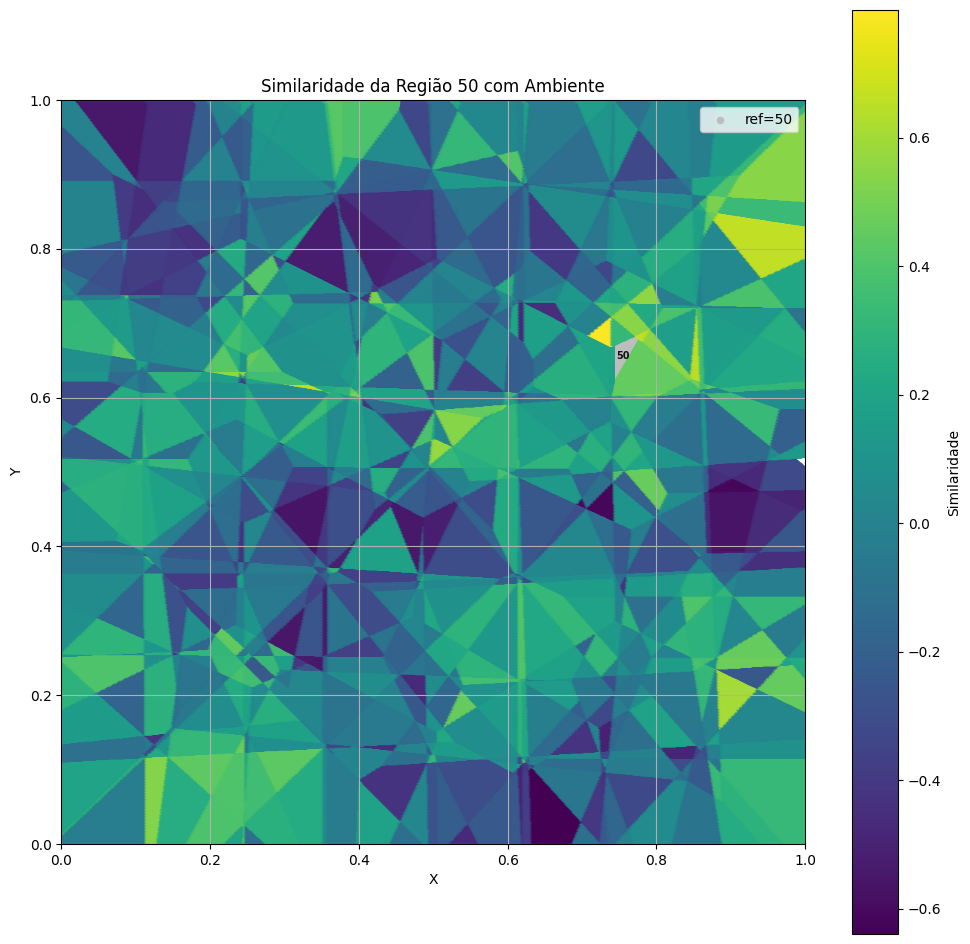

In [24]:
plot_similarity_to_group_from_matrix(apd, coss, grupo_ref=50, cmap="viridis", annotate_means=False)

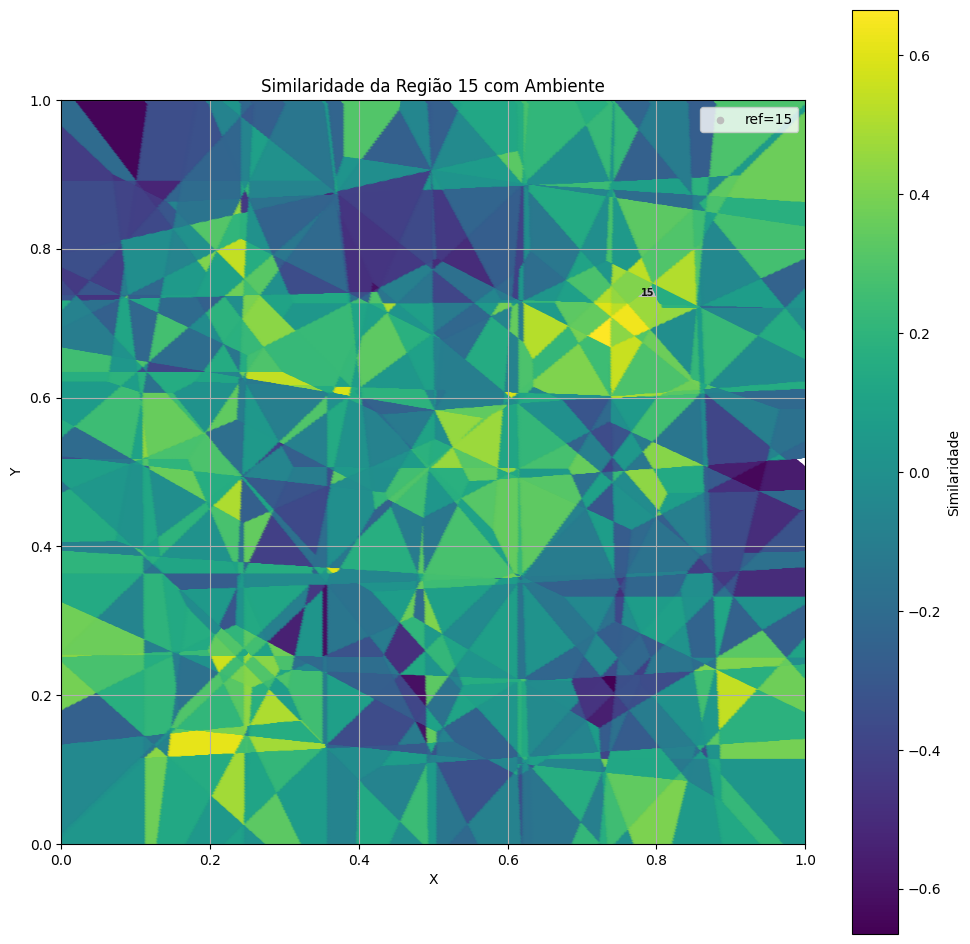

In [25]:
plot_similarity_to_group_from_matrix(apd, coss, grupo_ref=15, cmap="viridis", annotate_means=False)

# Head Projections

In [26]:
def plot_similarity_to_group_from_projec_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

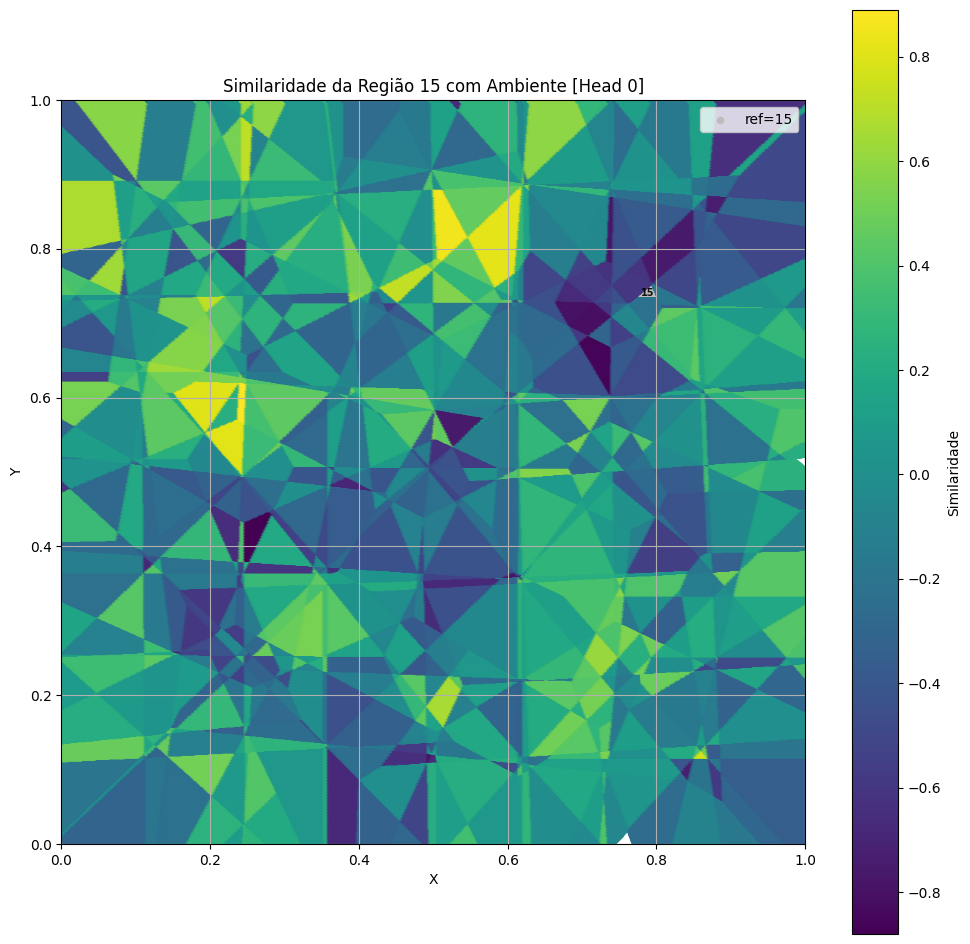

In [27]:
plot_similarity_to_group_from_projec_matrix(apd, head0, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=0)

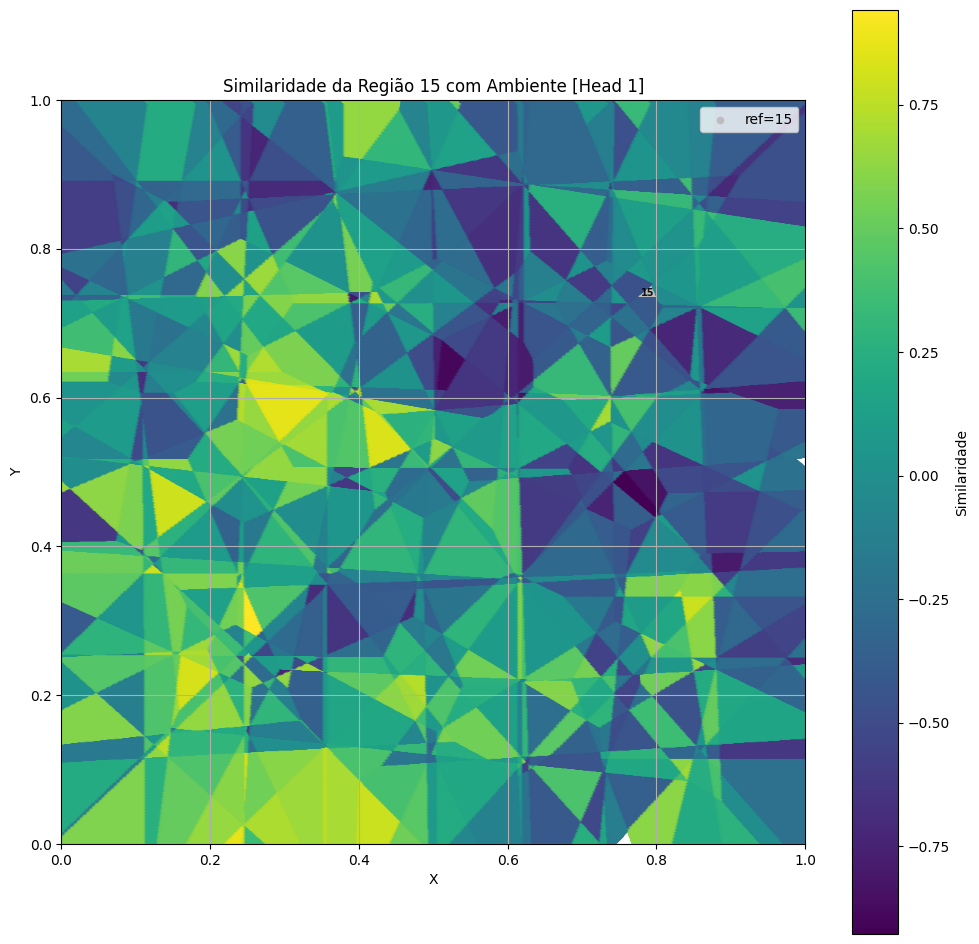

In [28]:
plot_similarity_to_group_from_projec_matrix(apd, head1, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=1)

# Head Attentions

In [10]:
def plot_similarity_to_group_from_attn_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

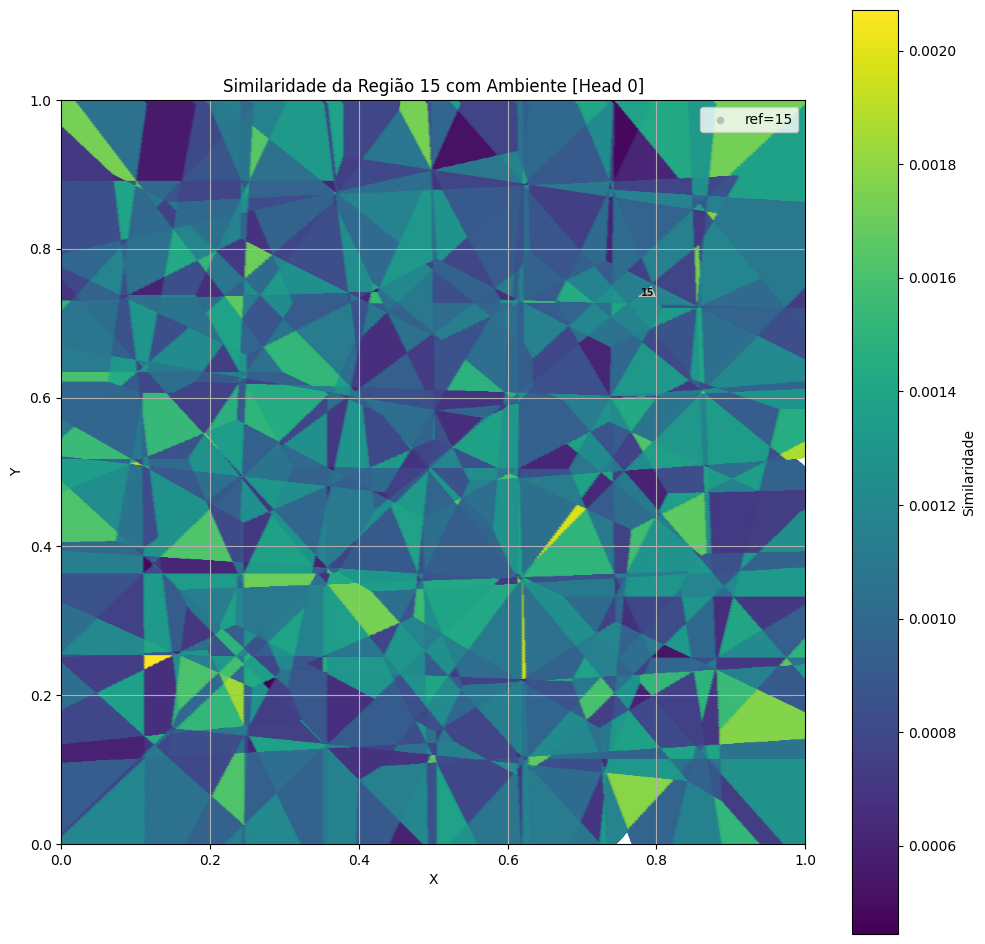

In [11]:
plot_similarity_to_group_from_attn_matrix(apd, head0_att, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=0)

In [14]:
apd['position_state_id'].max()

1056

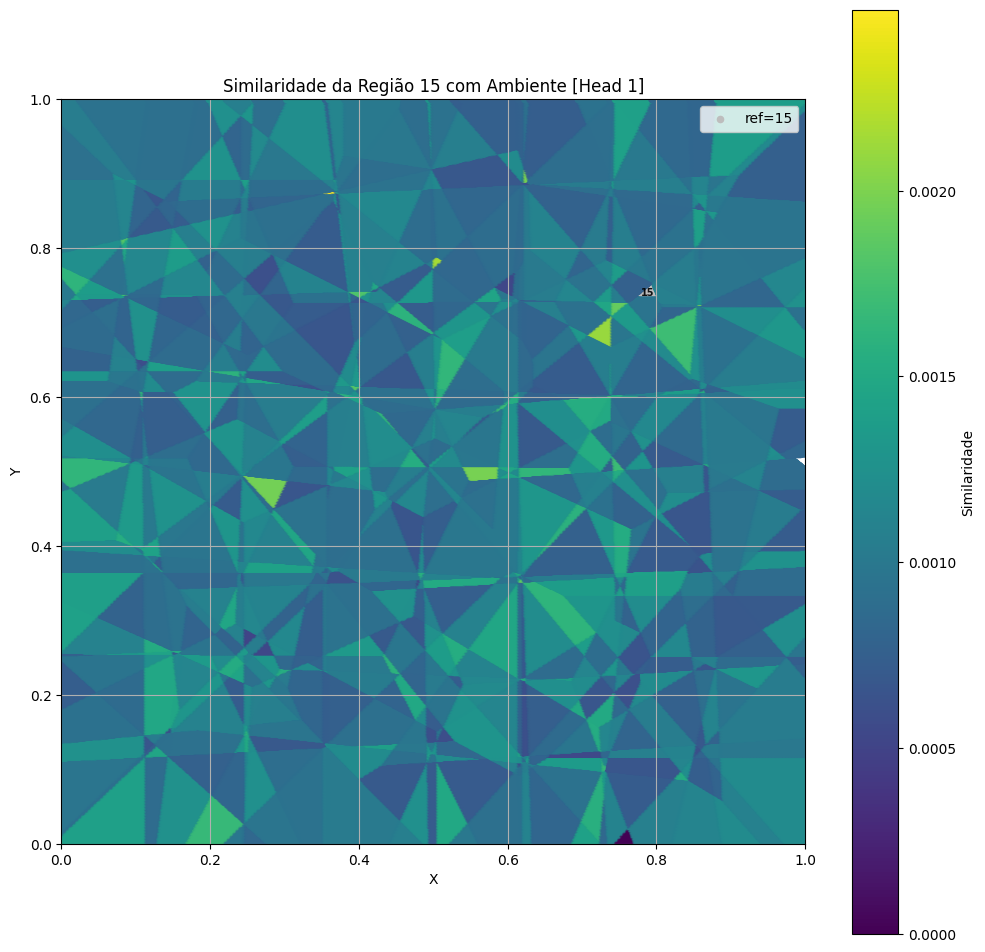

In [12]:
plot_similarity_to_group_from_attn_matrix(apd, head1_att, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=1)

# Head Attn w Pos

In [13]:
def plot_similarity_to_group_from_attn_matrix_w_pos(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

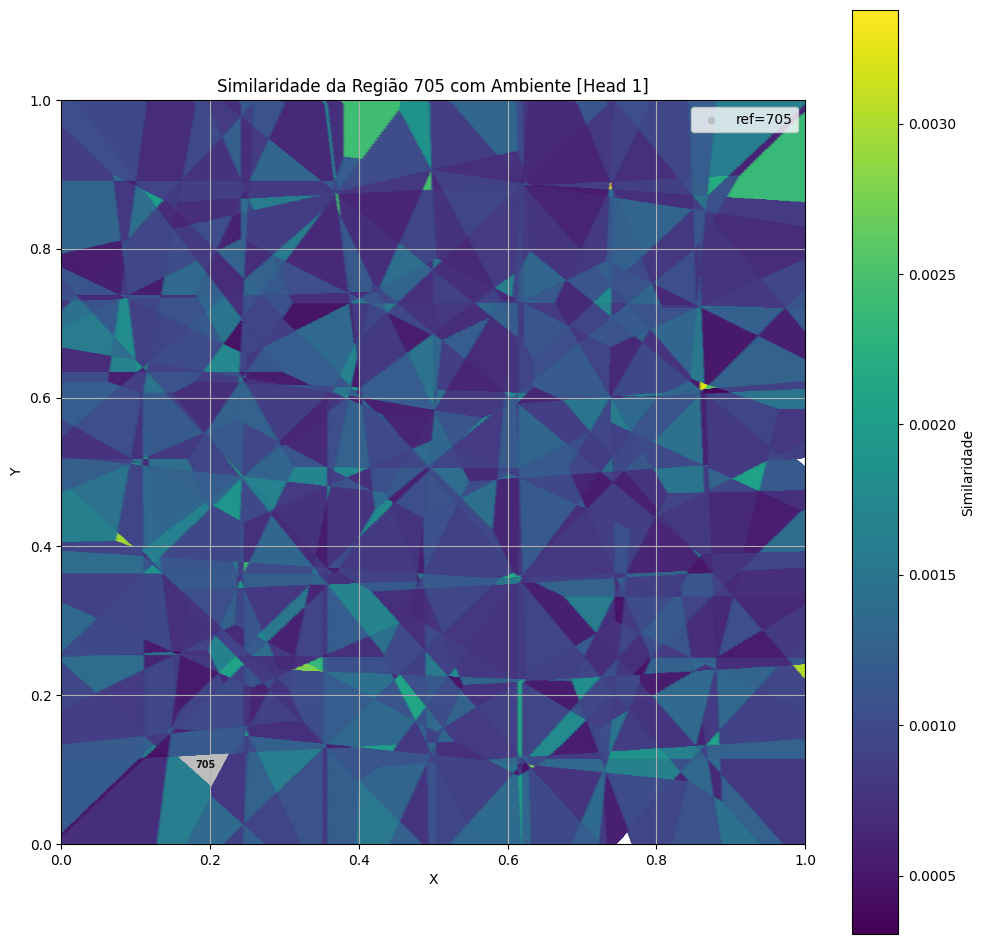

In [22]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1)

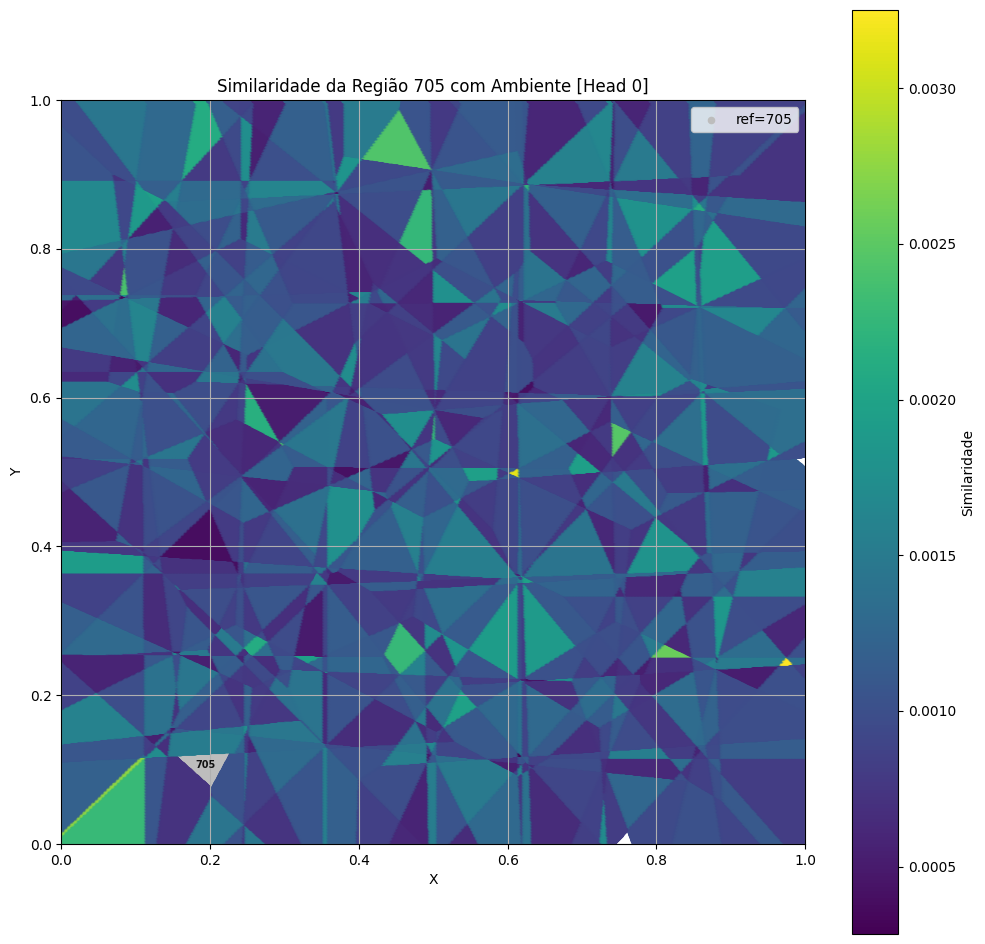

In [23]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0)

In [19]:
# plot_similarity_to_group_from_attn_matrix(apd, head1_att_pos, grupo_ref=806, cmap="viridis", annotate_means=False, num_head=1)

In [ ]:
head1_att_pos.iloc[705].sort_values(ascending=False).head()

341    0.002764
210    0.002684
770    0.002652
667    0.002426
775    0.002383
Name: 15, dtype: float64

In [ ]:
head0_att_pos.iloc[705].sort_values(ascending=False).head()

808    0.004574
138    0.003253
743    0.002719
624    0.002260
446    0.002227
Name: 15, dtype: float64

In [ ]:
head1_att_pos.iloc[15]['806']

0.0027919996

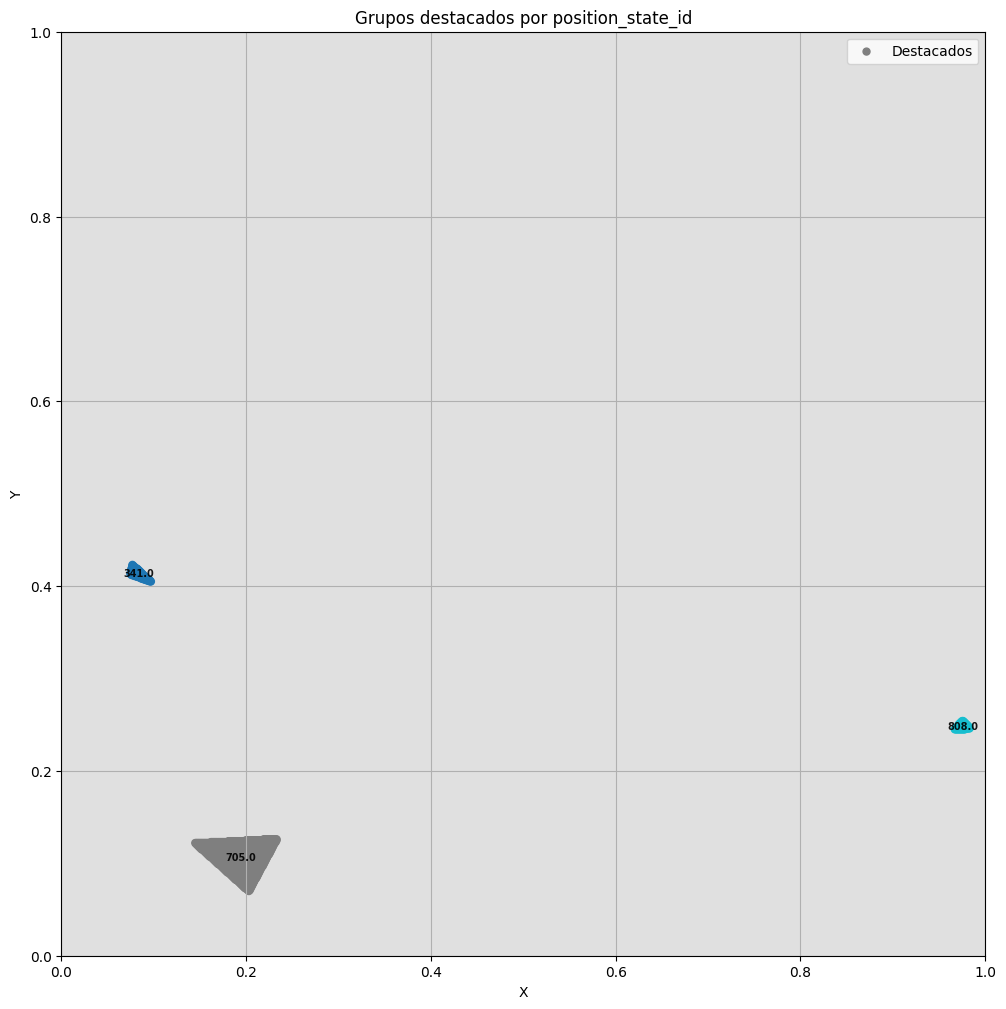

In [24]:
plot_position_states(apd, [705, 341, 808])

# Head Attn W Pos Softmax

In [16]:
def plot_similarity_to_group_from_attn_matrix_w_pos(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
    mode: str='',
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}, {mode}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

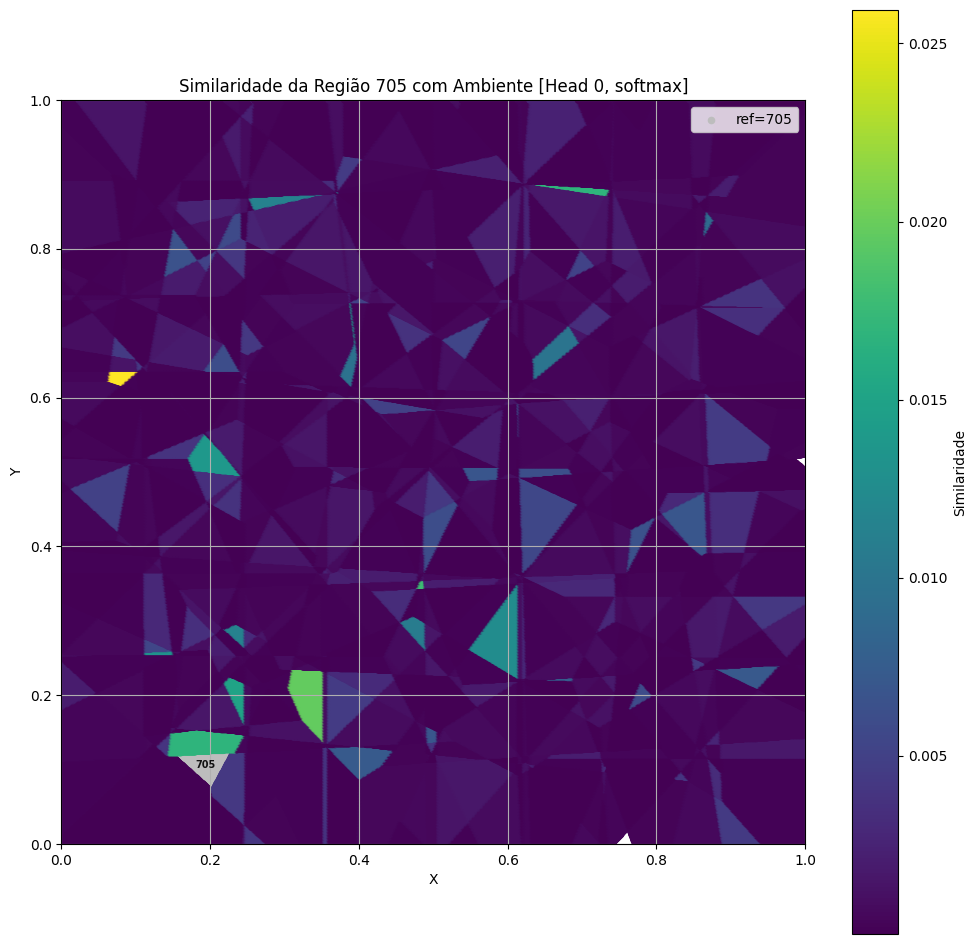

In [19]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_softmax, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='softmax')

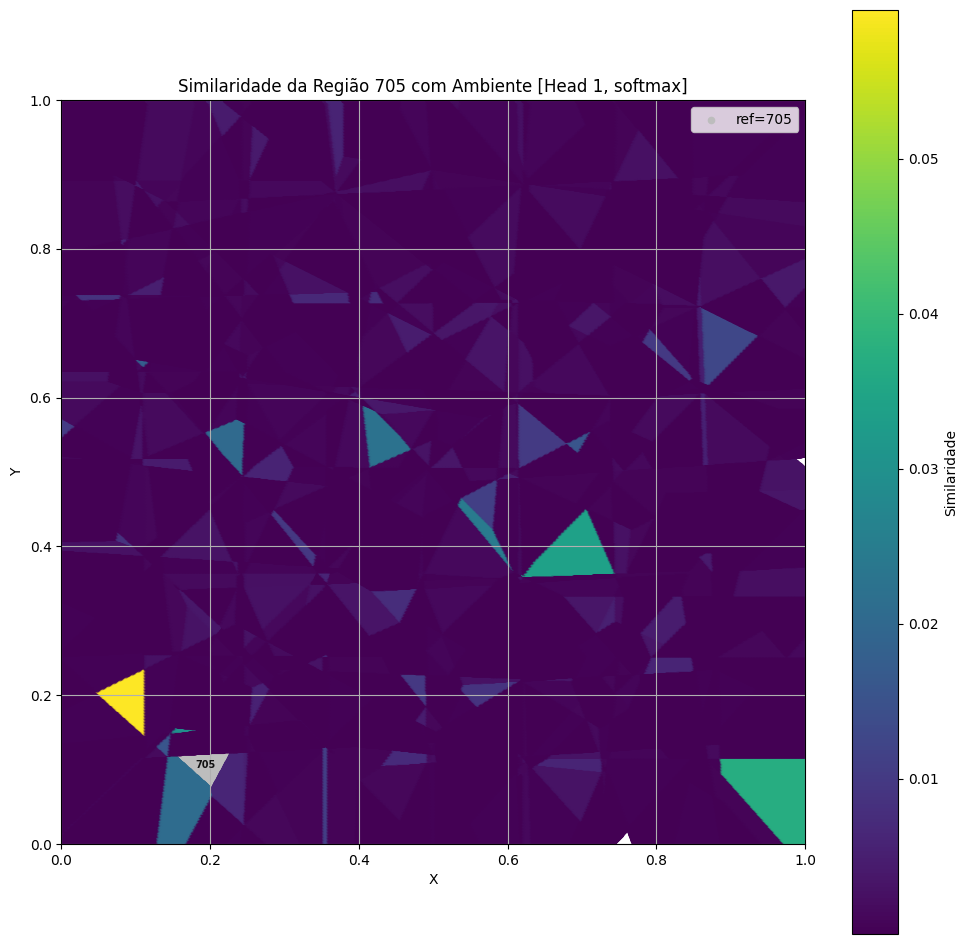

In [18]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_softmax, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='softmax')

# Head Attn W Pos Logit

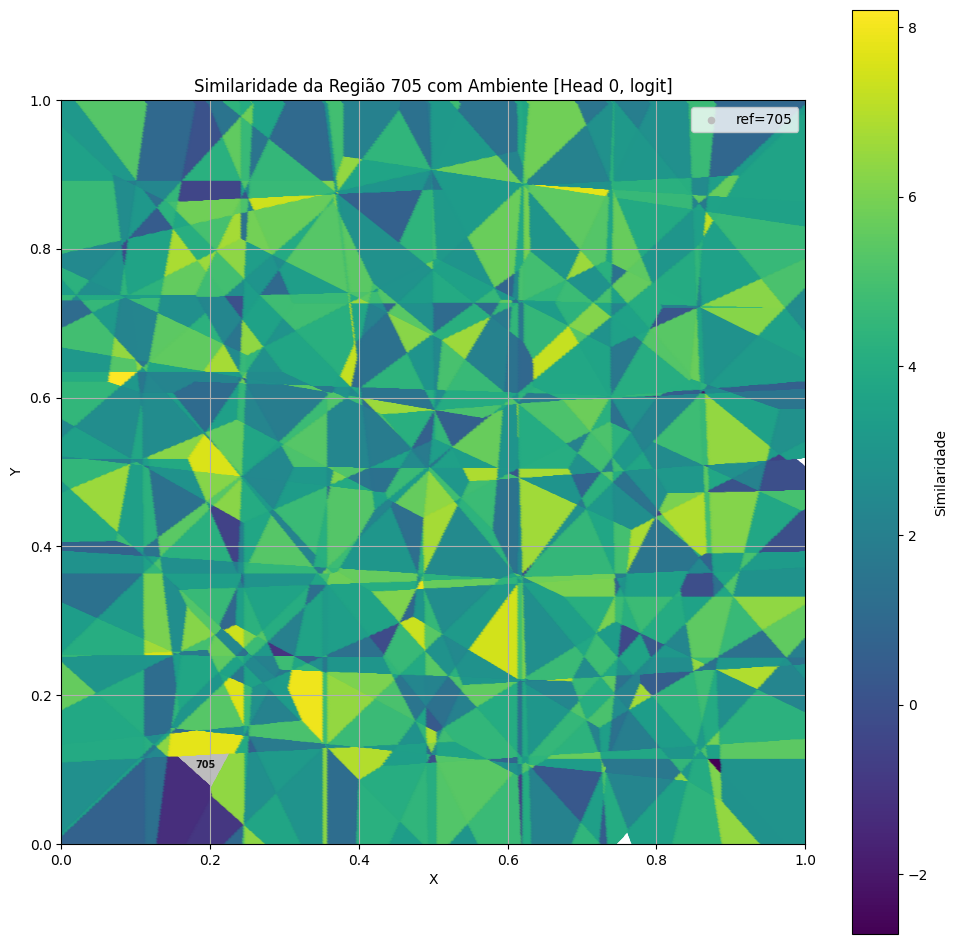

In [20]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_logit, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='logit')

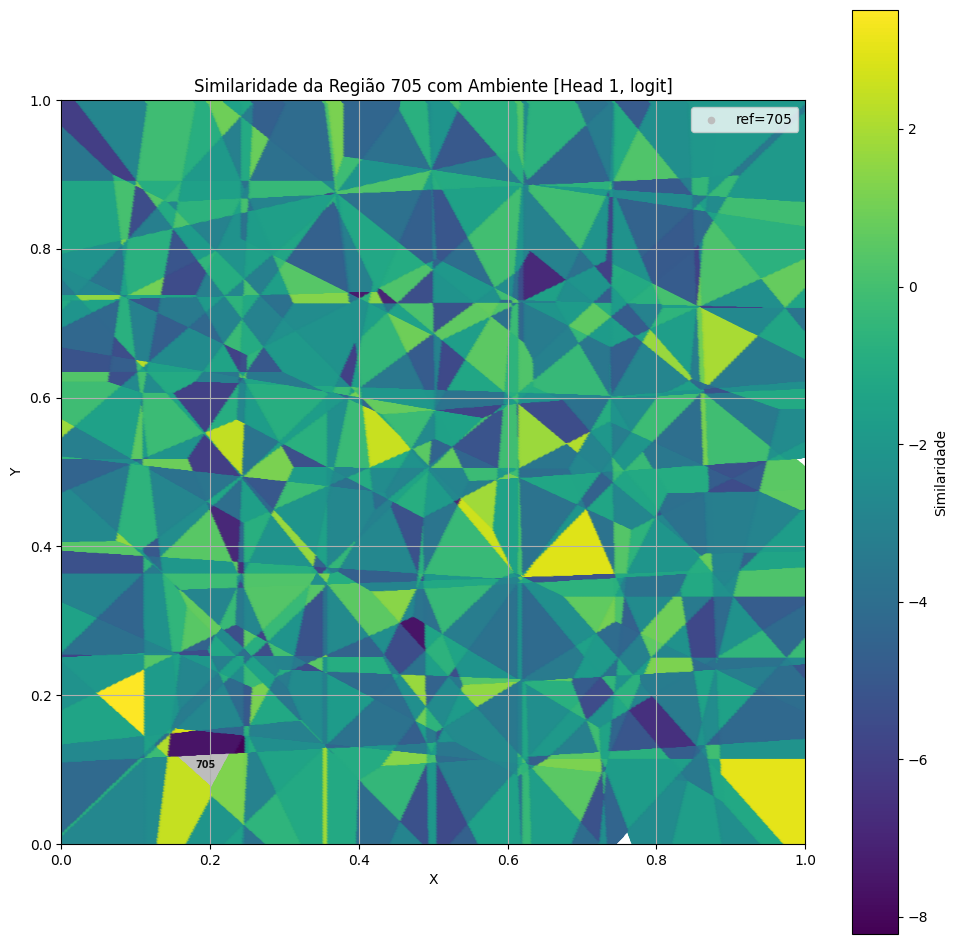

In [21]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_logit, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='logit')

# Head Attn W Pos Cossine

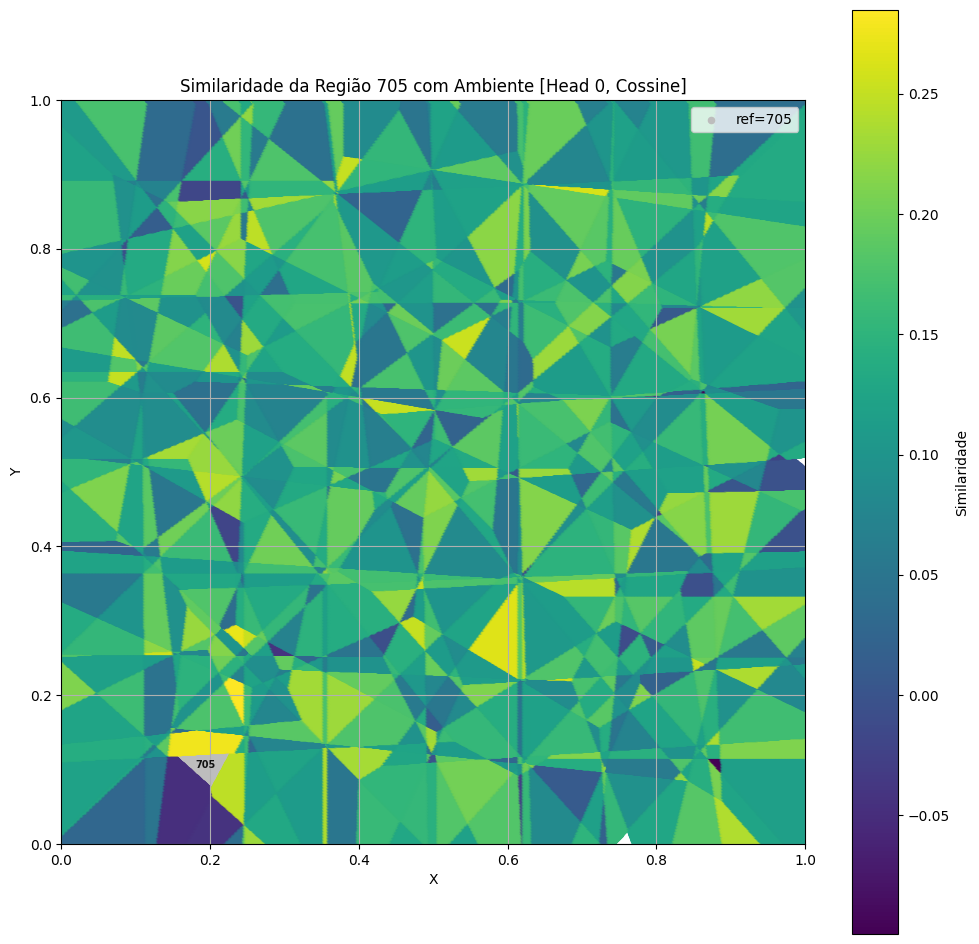

In [23]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_coss, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='Cossine')

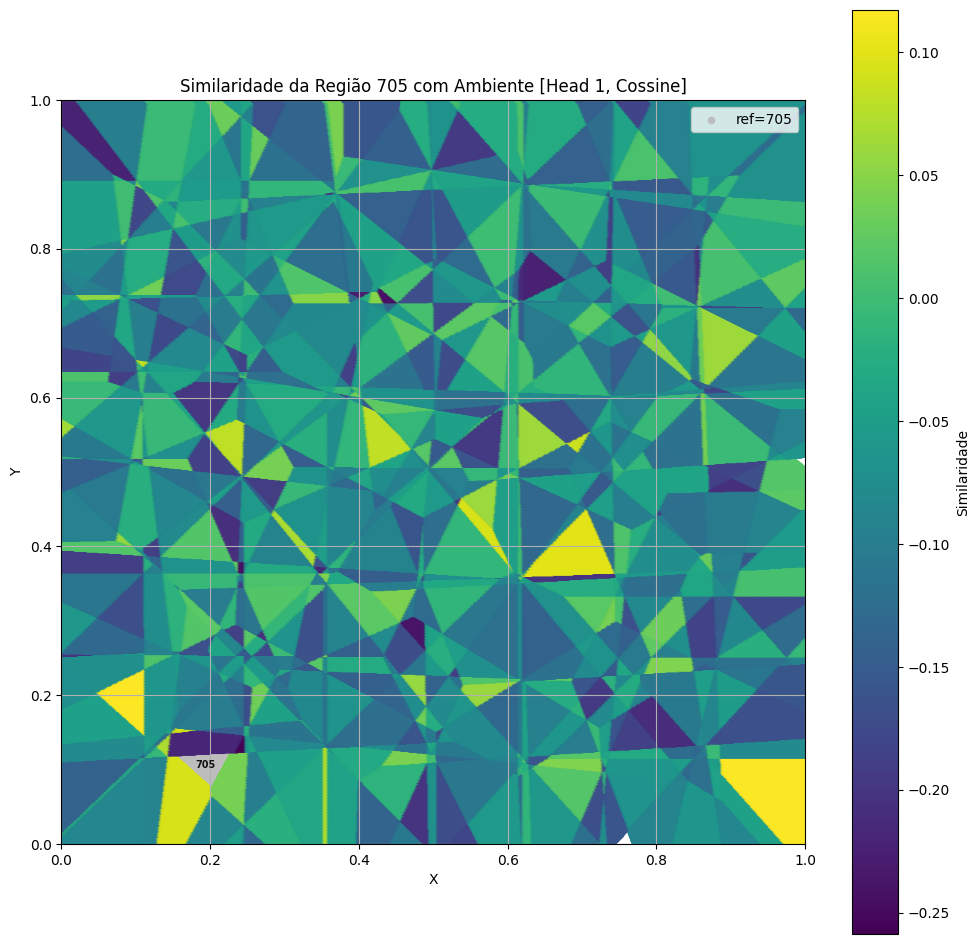

In [22]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_coss, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='Cossine')

# Imgs and GIFs

In [35]:
def gerar_graficos_expansao(
    apd,
    sequencias,
    pasta_destino="imgs",
    titulo_base="Passo",
    dpi=150,
    file_tag: str = '',
    modo: str = "mono",             # "mono" (novo) ou "colormap"
):
    """
    Aceita lista plana OU lista de listas.
    'modo' controla qual função de plot usar: "mono" (novo) ou 
    "colormap".
    """
    # normaliza entrada (plana -> cumulativa)
    if not isinstance(sequencias, (list, tuple)) or len(sequencias) == 0:
        raise ValueError("sequencias deve ser uma lista não vazia (plana ou de listas).")
    is_plana = all(not isinstance(x, (list, tuple)) for x in sequencias)
    sequencias_ids = [list(sequencias[:i+1]) for i in range(len(sequencias))] if is_plana \
                     else [list(s) for s in sequencias]

    os.makedirs(pasta_destino, exist_ok=True)
    caminhos = []
    use_colormap = (modo.lower() == "colormap")

    for step, ids in enumerate(sequencias_ids):
        caminho_arquivo = os.path.join(pasta_destino, f"{file_tag}etapa_{step:02}.png")
        title = f"{titulo_base} {step:02} | {ids[0]}->{ids[-1]}" if len(ids) >= 2 else f"{titulo_base} {step:02}"

        if use_colormap:
            plot_position_states_w_title(apd, grupos_destacados=ids, title=title)
        else:
            plot_position_states_emphasis_w_title(apd, grupos_destacados=ids, title=title)

        plt.savefig(caminho_arquivo, bbox_inches="tight", dpi=dpi)
        plt.close()
        caminhos.append(caminho_arquivo)

    return caminhos

In [36]:
import os, glob, re
from PIL import Image

def gerar_gif(pasta_imagens, file_prefix="", nome_gif="trajetoria_animada.gif", duracao=1000, loop=0):
    """
    Cria um GIF a partir dos PNGs em `pasta_imagens` cujo nome COMEÇA com `file_prefix`.

    Ex.: se você salvou como f"{file_tag}etapa_{step:02}.png",
         passe `file_prefix=file_tag` para pegar só esses frames.

    Parâmetros:
    - pasta_imagens : str | Path
    - file_prefix   : str  (prefixo do arquivo; ex.: "runA_" -> "runA_etapa_00.png")
    - nome_gif      : str  (nome do GIF final; salvo dentro de `pasta_imagens`)
    - duracao       : int  (ms entre frames)
    - loop          : int  (0 = infinito)

    Retorna:
    - caminho do GIF salvo (str) ou None se não encontrou imagens.
    """
    if not os.path.isdir(pasta_imagens):
        raise FileNotFoundError(f"Pasta não encontrada: {pasta_imagens}")

    padrao = os.path.join(pasta_imagens, f"{file_prefix}*.png")
    arquivos = glob.glob(padrao)

    if not arquivos:
        print(f"Nenhuma imagem encontrada com prefixo '{file_prefix}' em {pasta_imagens}.")
        return None

    # ordena por número de etapa_XX; se não casar, ordena por nome
    def key_etapa(p):
        m = re.search(r"etapa_(\d+)\.png$", os.path.basename(p))
        return (0, int(m.group(1))) if m else (1, os.path.basename(p))

    arquivos = sorted(arquivos, key=key_etapa)

    # carrega frames
    frames = [Image.open(p) for p in arquivos]
    try:
        out_path = os.path.join(pasta_imagens, nome_gif)
        frames[0].save(
            out_path,
            save_all=True,
            append_images=frames[1:],
            duration=duracao,
            loop=loop,
            optimize=True,
            disposal=2,   # ajuda a evitar ghosting entre frames
        )
        print(f"GIF salvo: {out_path}  ({len(frames)} frames)")
        return out_path
    finally:
        for im in frames:
            try:
                im.close()
            except Exception:
                pass


In [ ]:
[15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61]

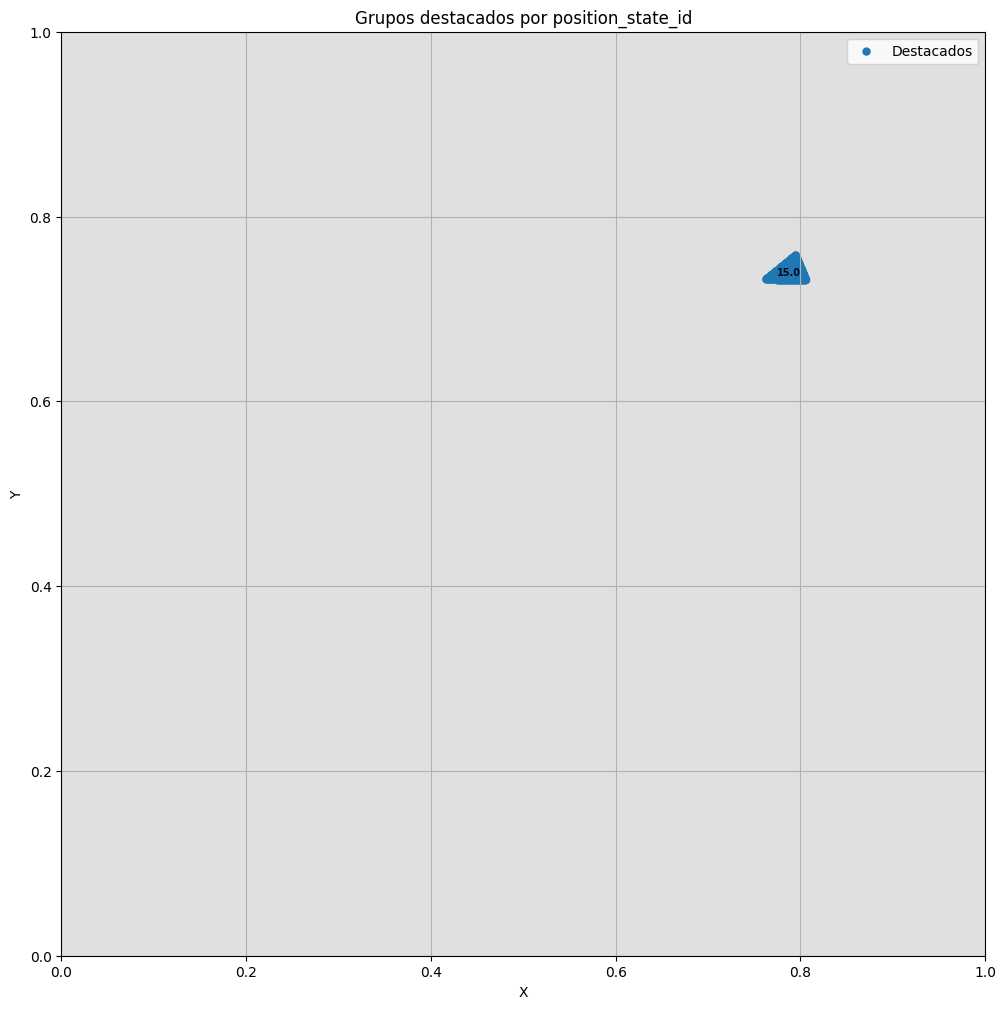

In [26]:
plot_position_states(apd, [15])

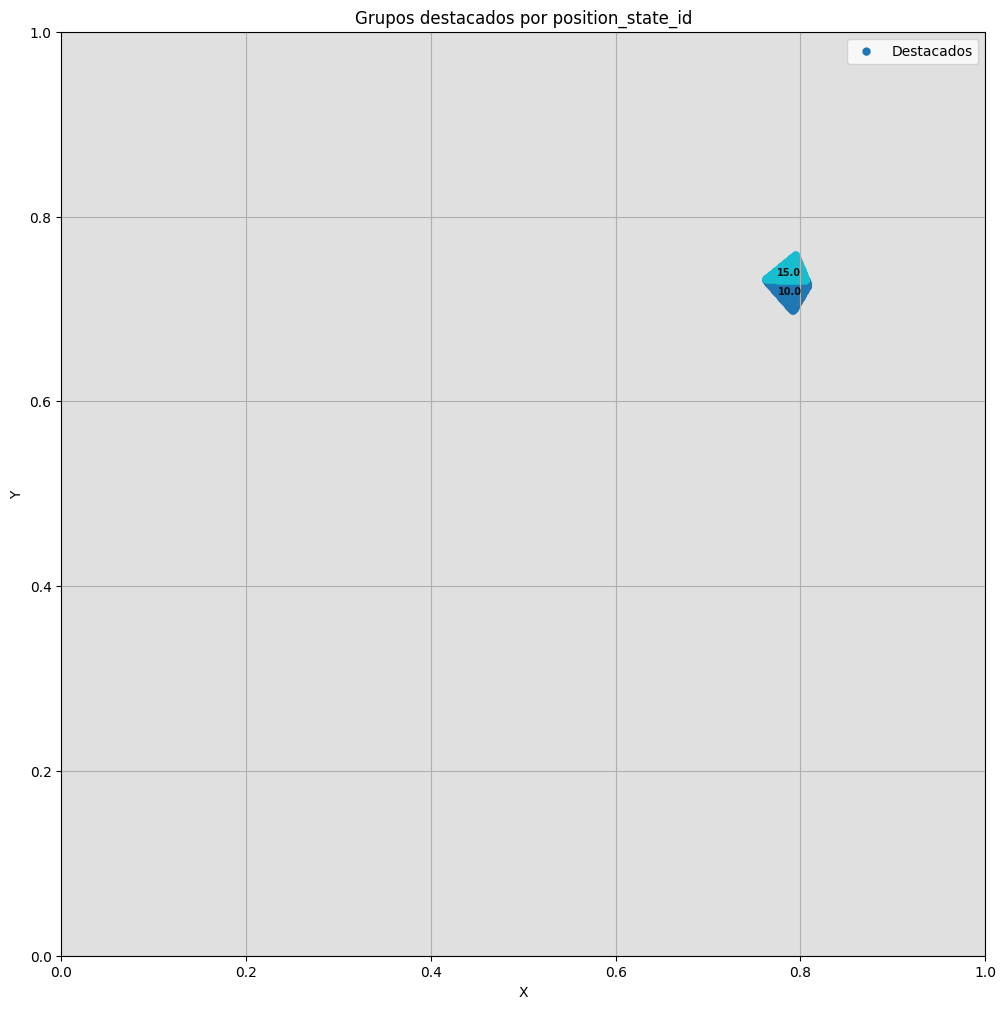

In [27]:
plot_position_states(apd, [15, 10])

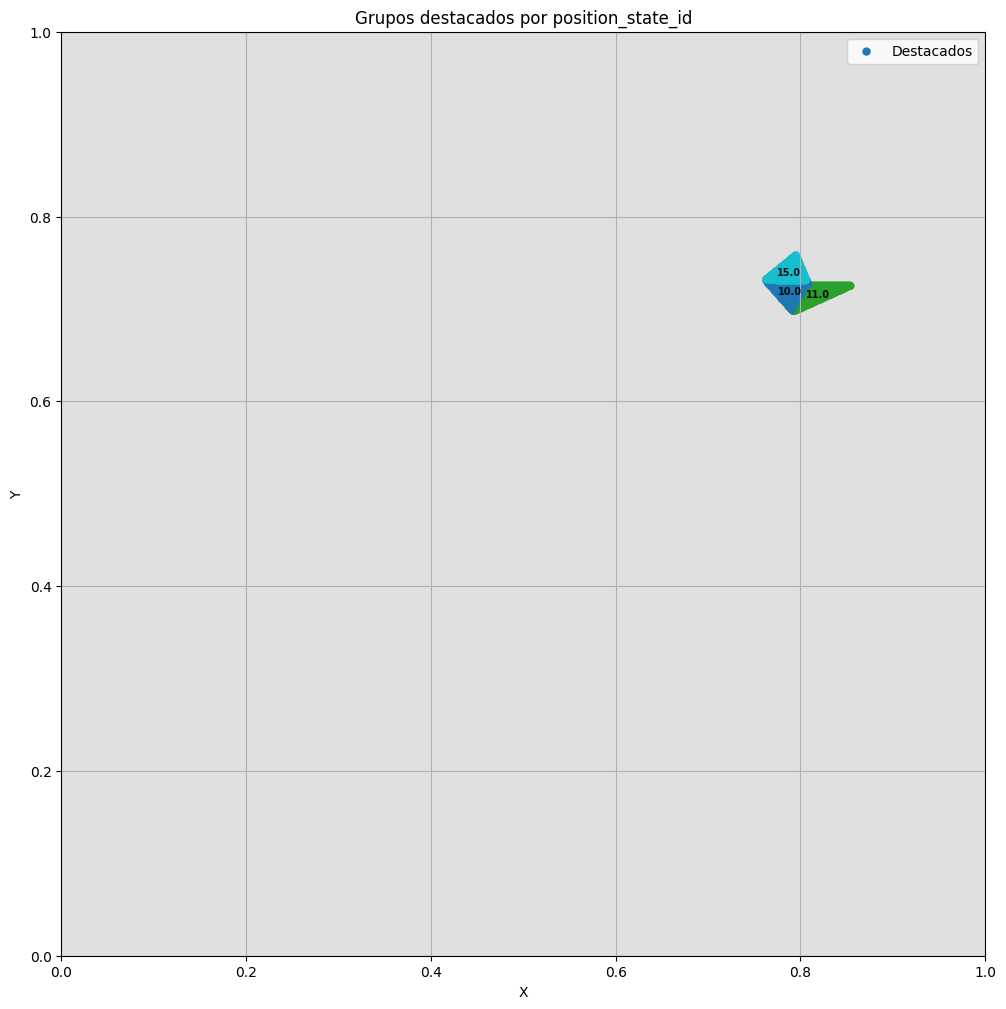

In [29]:
plot_position_states(apd, [15, 10, 11])

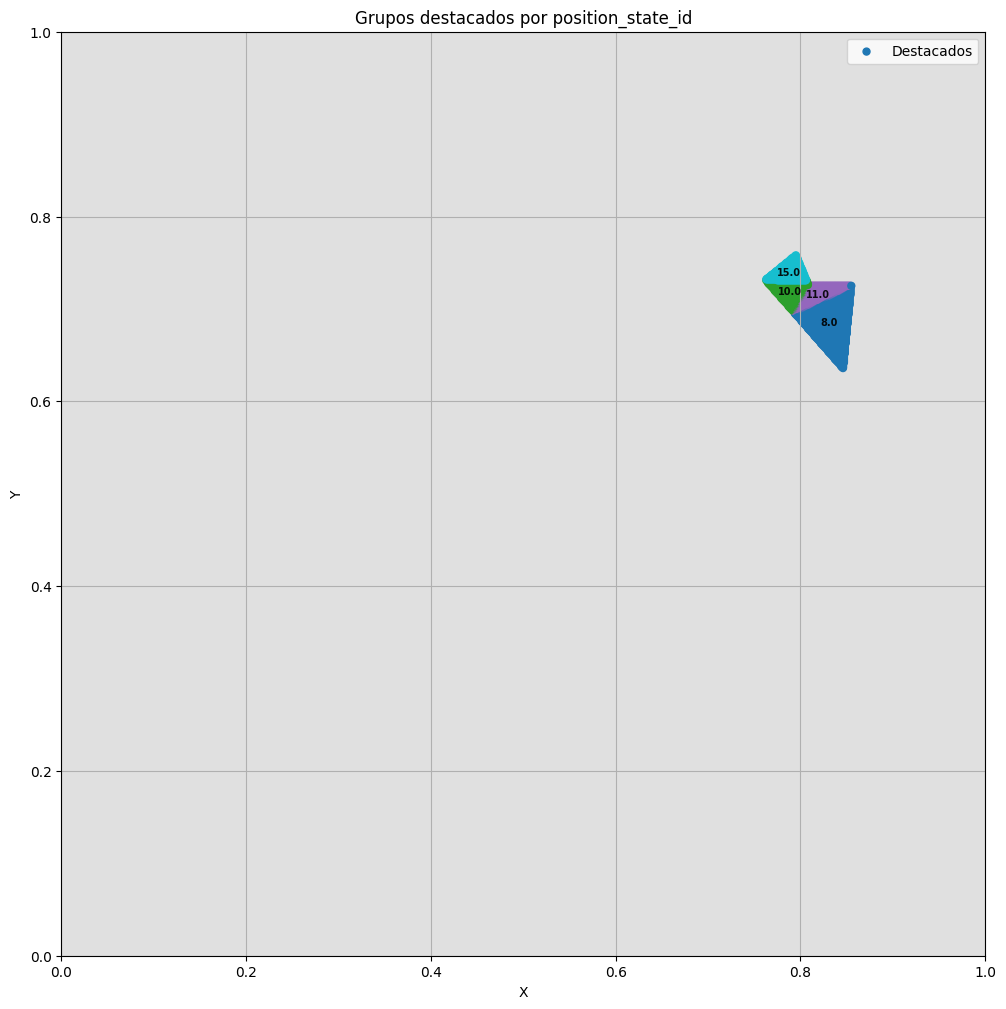

In [30]:
plot_position_states(apd, [15, 10, 11, 8])

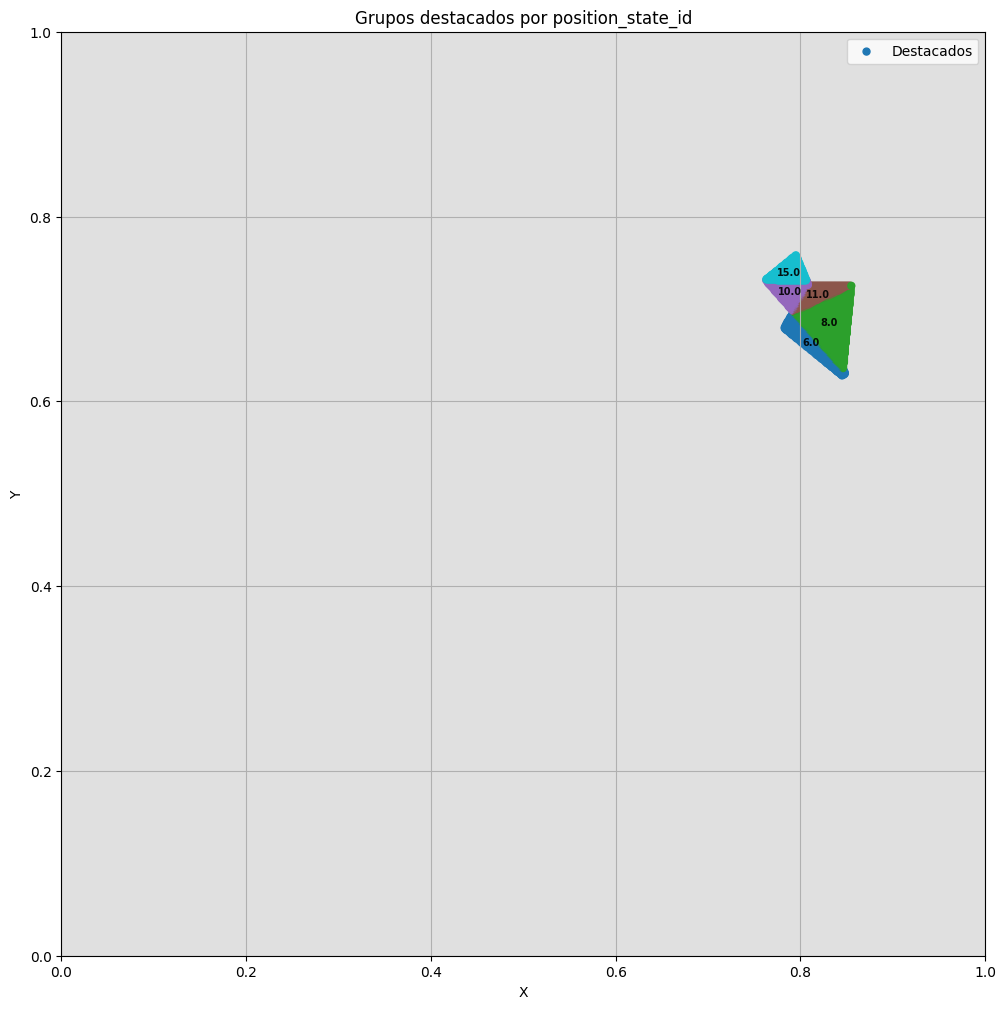

In [31]:
plot_position_states(apd, [15, 10, 11, 8, 6])

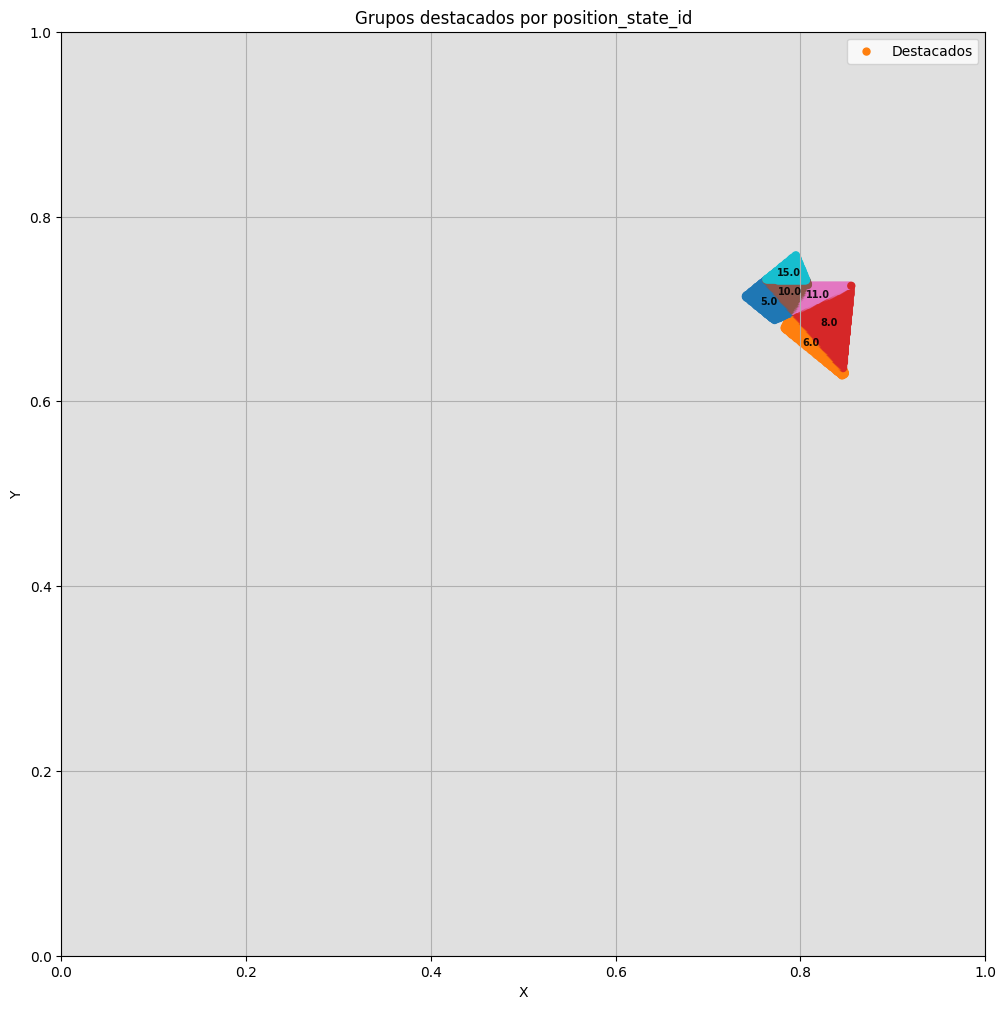

In [32]:
plot_position_states(apd, [15, 10, 11, 8, 6, 5])

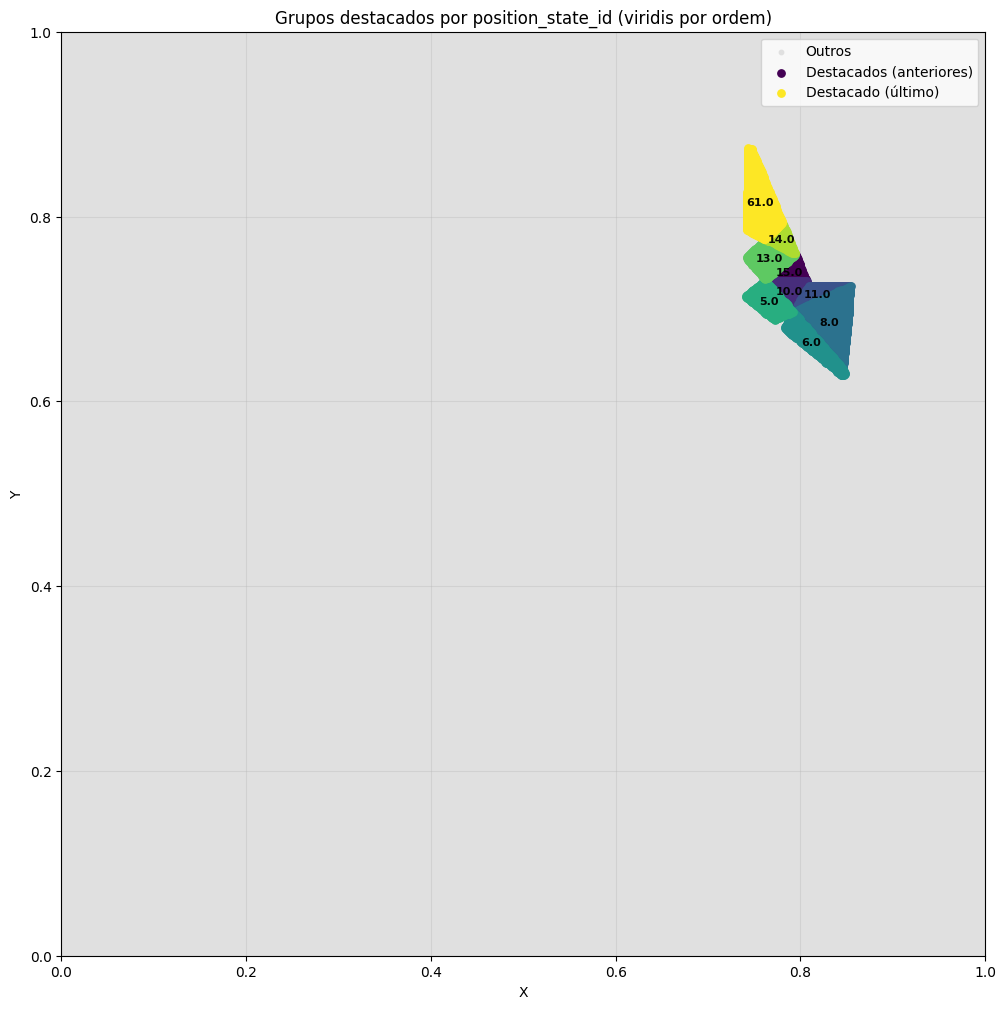

In [ ]:
plot_position_states_w_title(apd, [15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61])

In [19]:
gerar_graficos_expansao(apd, [15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61], titulo_base='Exemplo', modo='mono', file_tag='test_')

['imgs/test_etapa_00.png',
 'imgs/test_etapa_01.png',
 'imgs/test_etapa_02.png',
 'imgs/test_etapa_03.png',
 'imgs/test_etapa_04.png',
 'imgs/test_etapa_05.png',
 'imgs/test_etapa_06.png',
 'imgs/test_etapa_07.png',
 'imgs/test_etapa_08.png',
 'imgs/test_etapa_09.png',
 'imgs/test_etapa_10.png']

In [37]:
gerar_graficos_expansao(apd, [705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512], titulo_base='Exemplo', modo='mono', file_tag='test705_')

['imgs/test705_etapa_00.png',
 'imgs/test705_etapa_01.png',
 'imgs/test705_etapa_02.png',
 'imgs/test705_etapa_03.png',
 'imgs/test705_etapa_04.png',
 'imgs/test705_etapa_05.png',
 'imgs/test705_etapa_06.png',
 'imgs/test705_etapa_07.png',
 'imgs/test705_etapa_08.png',
 'imgs/test705_etapa_09.png',
 'imgs/test705_etapa_10.png']

In [39]:
# Se gerou com file_tag="GPT_Passo_"
gerar_gif("imgs", file_prefix="test_", nome_gif="test_trajetoria_gpt.gif", duracao=600, loop=0)

GIF salvo: imgs/test_trajetoria_gpt.gif  (11 frames)


'imgs/test_trajetoria_gpt.gif'

In [40]:
# Se gerou com file_tag="GPT_Passo_"
gerar_gif("imgs", file_prefix="test705_", nome_gif="test705_trajetoria_gpt.gif", duracao=600, loop=0)

GIF salvo: imgs/test705_trajetoria_gpt.gif  (11 frames)


'imgs/test705_trajetoria_gpt.gif'

# Probs Distribs

In [29]:
def plot_prob_from_probs_df_w_pos(
    apd: pd.DataFrame,
    probs_df: pd.DataFrame,     # index: token_id (int ou str numérica), columns: "Passo 01", ...
    passo,                      # str ("Passo 04") OU int (0 = primeira coluna)
    token_atual: int,           # id do token atual (marcado em cinza quando colorir_token_atual_por_prob=False)
    cmap: str = "viridis",
    annotate_means: bool = False,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head: int = 0,
    mode: str = "",
    colorir_token_atual_por_prob: bool = False,   # <--- NOVO
):
    """
    Colore os pontos de `apd` pela probabilidade do token no `passo` escolhido.
    Se `colorir_token_atual_por_prob=True`, o `token_atual` NÃO é pintado de cinza
    e sim colorido conforme a sua probabilidade, apenas com anotação do id.
    """
    # --- saneamento: garantir que o índice (tokens) seja int compatível com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        return df

    probs_df = _to_int_index(probs_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"

    # resolve a coluna do passo
    col = probs_df.columns[passo] if isinstance(passo, int) else passo
    if col not in probs_df.columns:
        raise ValueError(f"Coluna '{col}' não encontrada em probs_df")

    # separa atual e demais
    is_ref = (apd["position_state_id"] == token_atual)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de probabilidades no passo escolhido (indexada por id)
    prob_series = probs_df[col]  # pandas Series: index = ids, values = probs

    # mapeia probabilidade
    df_outros["prob"] = df_outros["position_state_id"].map(prob_series)

    # --- decide o conjunto que será colorido por probabilidade ---
    if colorir_token_atual_por_prob:
        if not df_ref.empty:
            df_ref_col = df_ref.copy()
            df_ref_col["prob"] = df_ref_col["position_state_id"].map(prob_series)
            data_to_scatter = pd.concat([df_outros, df_ref_col], ignore_index=True)
        else:
            data_to_scatter = df_outros
    else:
        data_to_scatter = df_outros

    # plot
    plt.figure(figsize=(12, 12))

    # 1) token atual:
    if not colorir_token_atual_por_prob:
        # pinta em cinza + anota
        if not df_ref.empty:
            plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"token={token_atual}")
            plt.annotate(str(token_atual),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)
    else:
        # não pinta cinza; apenas anota (ele será colorido por prob no scatter abaixo)
        if not df_ref.empty:
            plt.annotate(str(token_atual),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) coloridos por probabilidade (NaN em 'prob' são ignorados pelo scatter)
    if not data_to_scatter.empty:
        sc = plt.scatter(
            data_to_scatter["X"], data_to_scatter["Y"],
            c=data_to_scatter["prob"], cmap=cmap, s=s_outros
        )
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Probabilidade ({col})")

    # 3) anotação das médias por grupo (≠ token atual)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X"); plt.ylabel("Y")
    plt.title(f"Probabilidade no {col}")
    plt.xlim(0, 1); plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")

    # legenda (só aparece se algo tiver label — ex.: token cinza quando aplicável)
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        plt.legend(handles, labels, loc="upper right")

    plt.show()


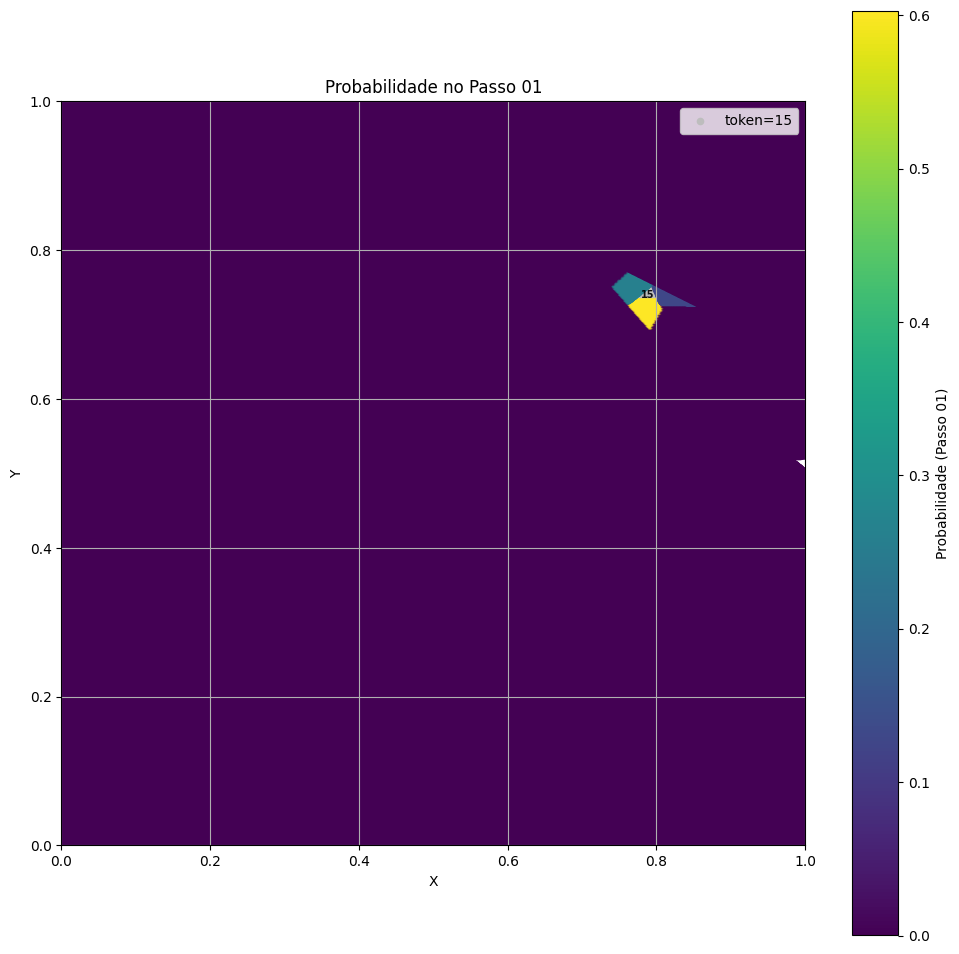

In [30]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=0, token_atual=15,)

In [23]:
distribs_probs.head()

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.662680e-06,3.177991e-06,4.009456e-06,1.145890e-06,2.520847e-06,0.000004,5.748174e-06,8.418958e-06,1.464796e-07,0.000228
1,2.157076e-07,1.543836e-07,1.201682e-07,5.364881e-08,7.375746e-07,0.000002,4.088467e-07,4.277045e-07,1.134515e-08,0.000080
2,1.828289e-04,1.275089e-05,1.952099e-06,6.359525e-07,6.182945e-04,0.000040,6.925649e-05,3.427698e-05,2.078097e-08,0.000072
3,7.179261e-06,5.824850e-01,8.121820e-05,5.431971e-01,3.116338e-06,0.000618,9.700832e-04,7.698964e-04,1.833539e-07,0.000396
4,1.745968e-05,2.277800e-05,6.613256e-06,8.439538e-06,5.750006e-06,0.000010,5.122279e-06,3.306124e-06,5.105923e-08,0.000084


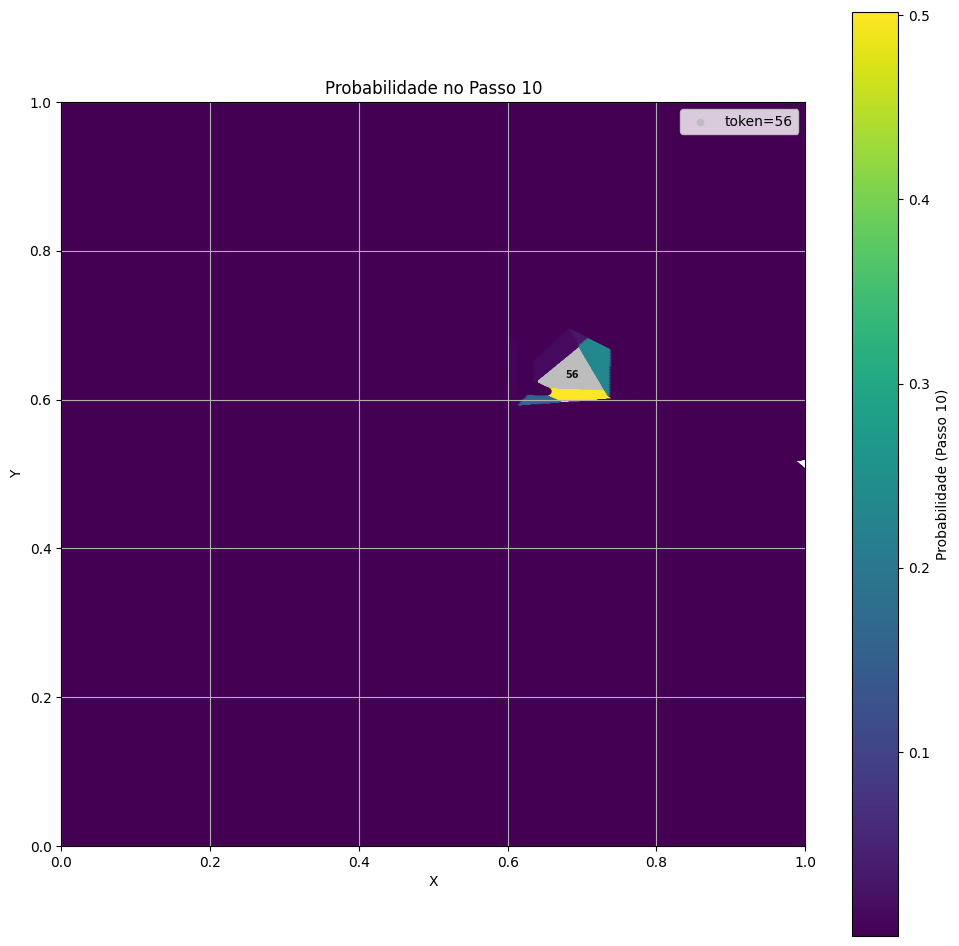

In [26]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=9, token_atual=56,)

In [32]:
[705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512]

[705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512]

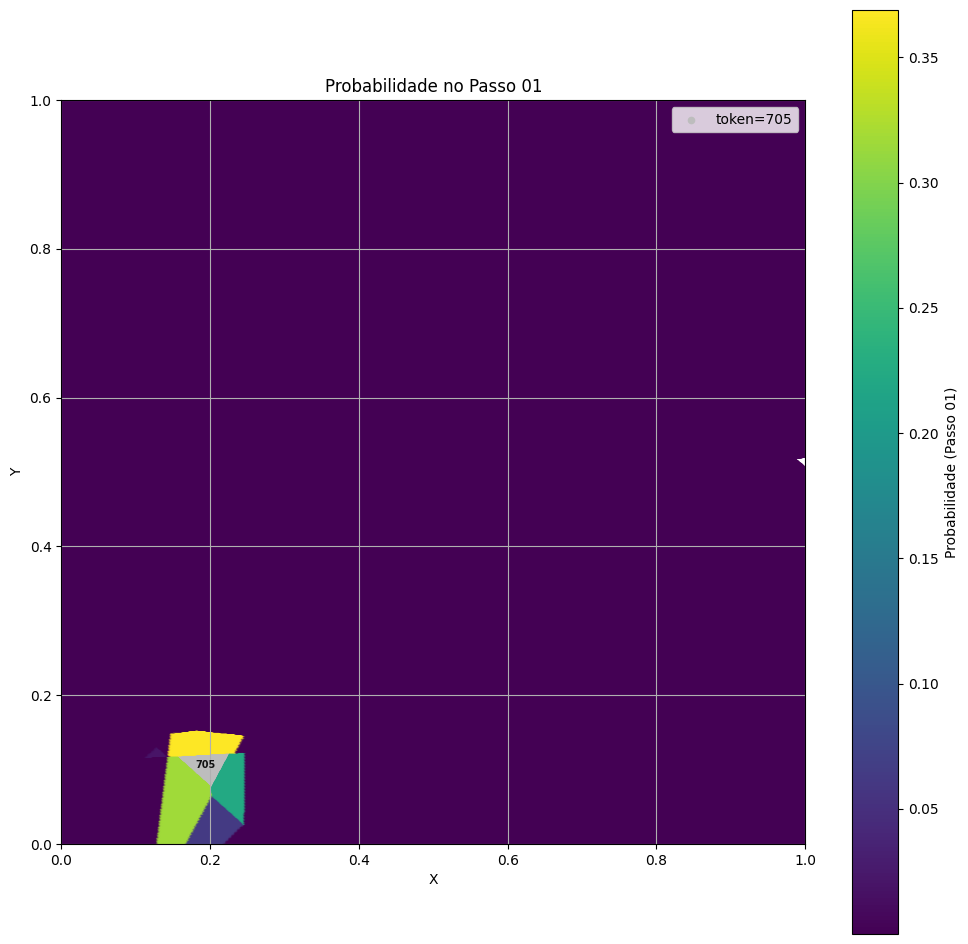

In [31]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=0, token_atual=705,)

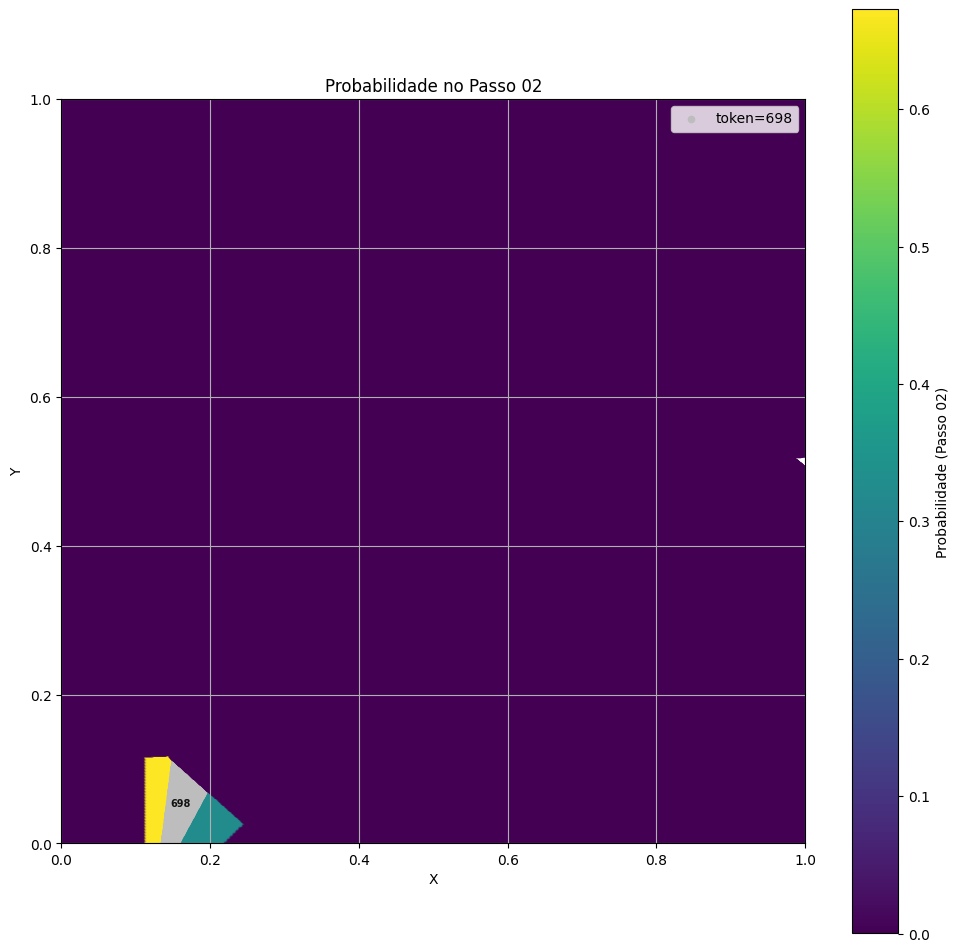

In [33]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=1, token_atual=698,)

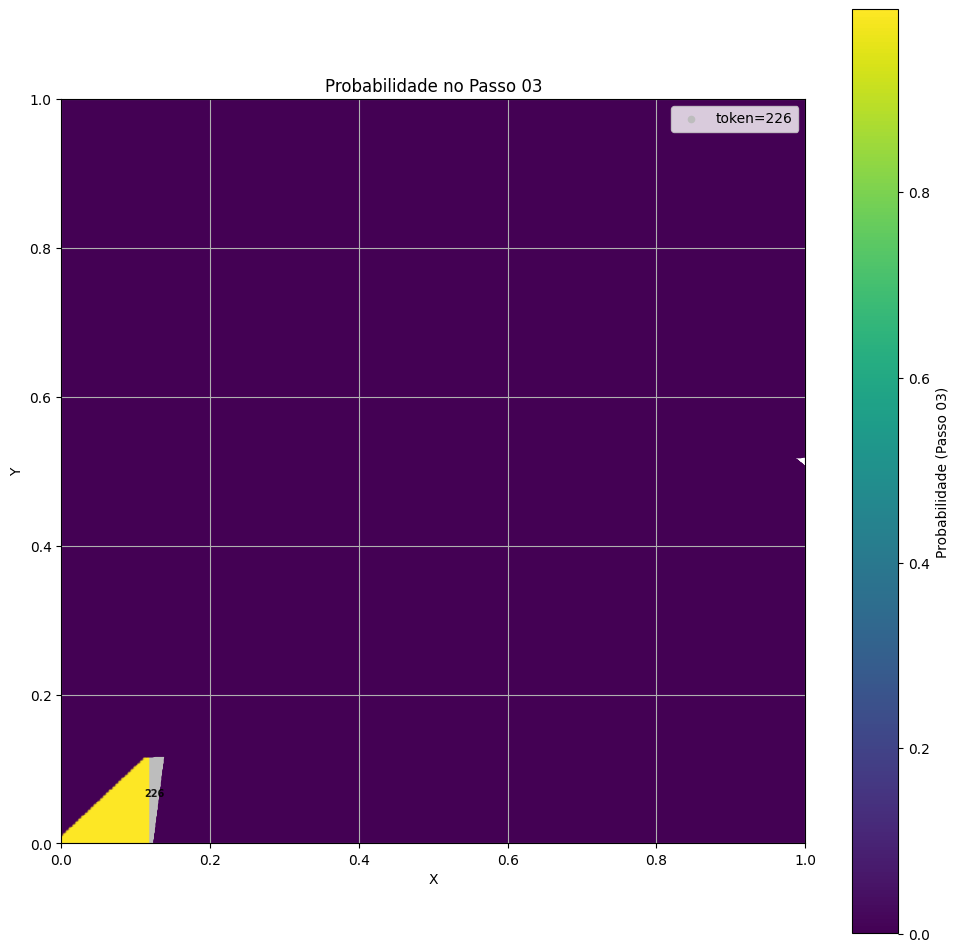

In [41]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=2, token_atual=226,)

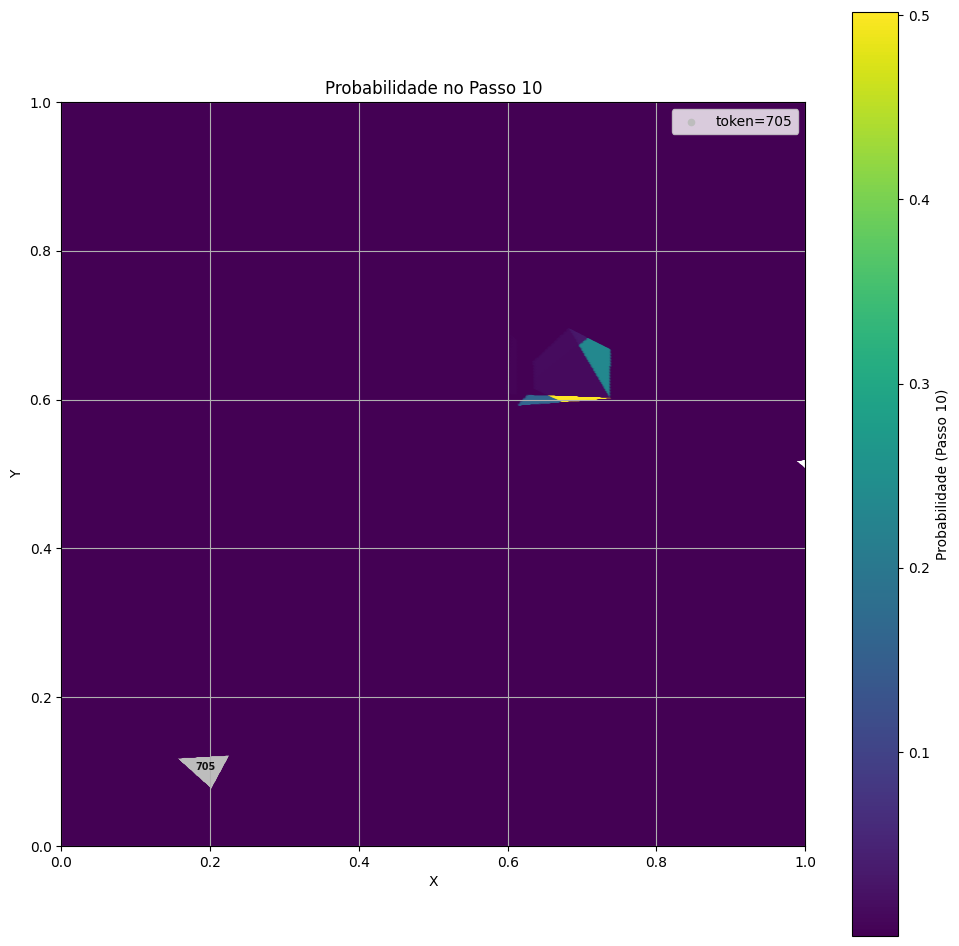

In [27]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=9, token_atual=705,)

# Logits Distrib

In [15]:
def plot_logits_from_logits_df_w_pos(
    apd: pd.DataFrame,
    logits_df: pd.DataFrame,    # index: token_id (int ou str numérica), columns: "Passo 01", ...
    passo,                      # str ("Passo 04") OU int (0 = primeira coluna)
    token_atual: int,           # id do token atual (marcado em cinza)
    cmap: str = "viridis",
    annotate_means: bool = False,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head: int = 0,
    mode: str = "",
):
    """
    Colore os pontos de `apd` pelo **logit** do token no `passo` escolhido.
    O `token_atual` é plotado em cinza.
    """
    # --- saneamento: garantir que o índice (tokens) seja int compatível com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        return df

    logits_df = _to_int_index(logits_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"

    # resolve a coluna do passo
    col = logits_df.columns[passo] if isinstance(passo, int) else passo
    if col not in logits_df.columns:
        raise ValueError(f"Coluna '{col}' não encontrada em logits_df")

    # separa atual e demais
    is_ref = (apd["position_state_id"] == token_atual)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de logits no passo escolhido (indexada por id)
    logit_series = logits_df[col]

    # mapeia cada position_state_id -> logit no passo; ids ausentes viram NaN
    # substitui ±inf (ex.: após top-k) por NaN para o scatter ignorar
    df_outros["logit"] = df_outros["position_state_id"].map(logit_series).replace([np.inf, -np.inf], np.nan)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) token atual em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"token={token_atual}")
        plt.annotate(str(token_atual),
                     (df_ref["X"].mean(), df_ref["Y"].mean()),
                     fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pelo logit (NaN são ignorados pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["logit"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Logit ({col})")

    # 3) anotação das médias por grupo (≠ token atual)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Logits de Cada Região no {col}")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()


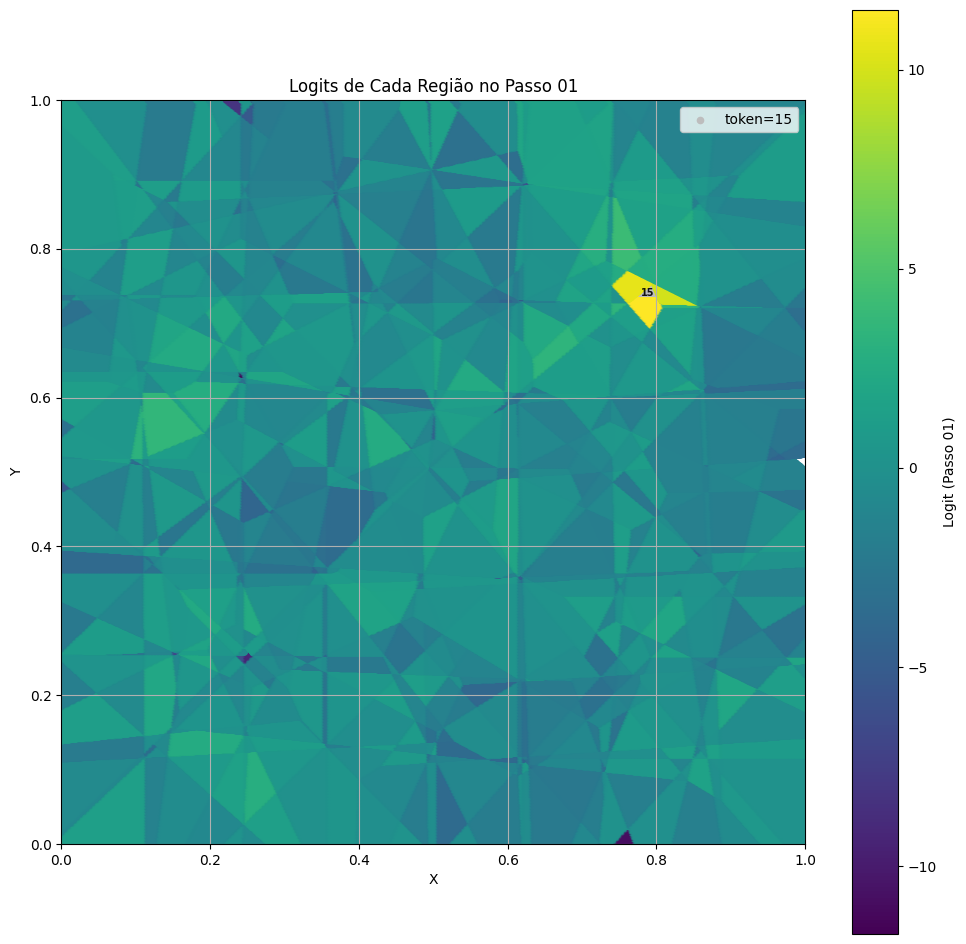

In [16]:
plot_logits_from_logits_df_w_pos(apd, distribs_logits, passo=0, token_atual=15)

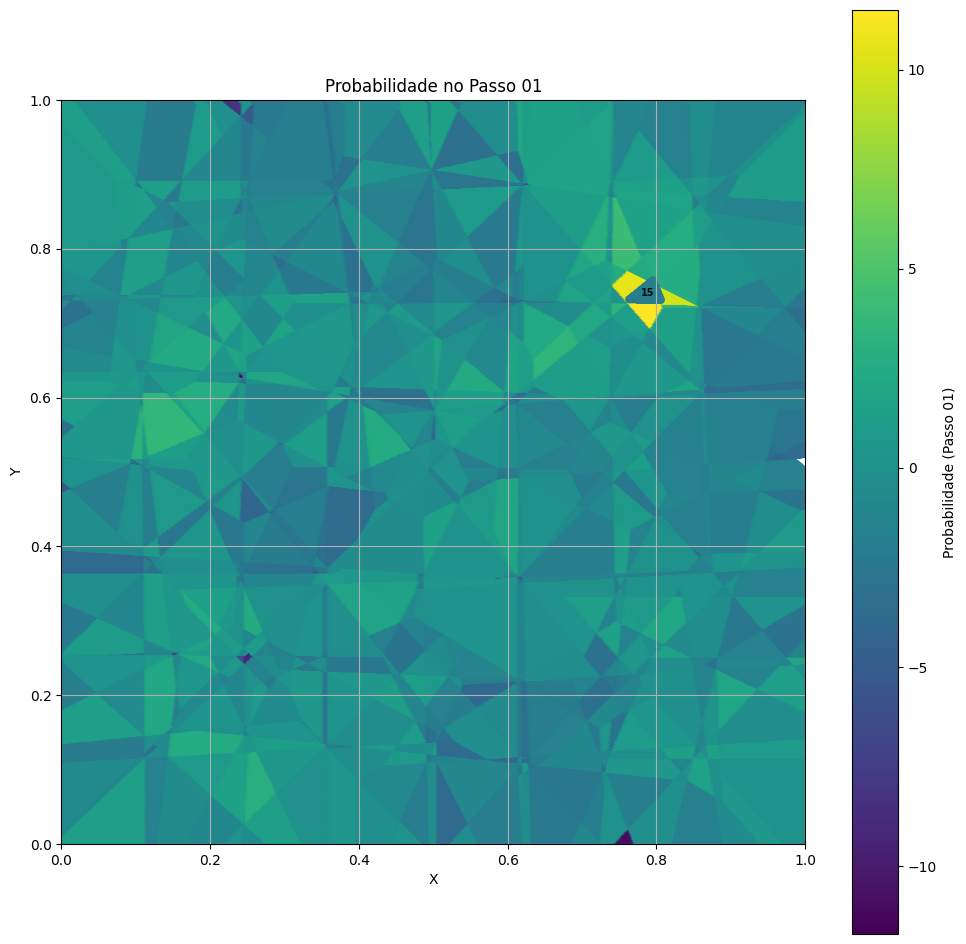

In [21]:
plot_prob_from_probs_df_w_pos(apd, distribs_logits, passo=0, token_atual=15, colorir_token_atual_por_prob=True)

# Smoothed Prob

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def compute_prob_grid_from_apd(
    apd: pd.DataFrame,
    probs_df: pd.DataFrame,     # index: token_id (int ou str numérica), columns: "Passo 01", ...
    passo,                      # str ("Passo 04") OU int (0 = primeira coluna)
    resolucao: float = 0.01,    # tamanho da célula em X e Y
    plot_heat: bool = True,
    cmap: str = "viridis",
    alpha: float = 1.0,
    title: str = None,
):
    """
    Cria uma grade (x,y) com 'resolucao' (ex.: 0.01 -> 100x100 células).
    Para cada célula, busca os pontos de 'apd' que caem nela, usa seus tokens
    (position_state_id) para mapear as probabilidades em 'probs_df[passo]' e
    calcula a MÉDIA dessas probabilidades. Retorna o array 'heat' e um DataFrame
    com o resumo por célula. Opcionalmente plota um heatmap.

    Retorna:
      heat: np.ndarray shape (nb, nb) com médias por célula (NaN se vazia)
      cells_df: DataFrame com colunas:
        ['xbin','ybin','x0','x1','y0','y1','mean_prob','count']
    """
    # --- saneamento: índice de probs_df como int
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        return df

    probs_df = _to_int_index(probs_df)

    # checagens
    req = {"X","Y","position_state_id"}
    if not req.issubset(apd.columns):
        raise ValueError(f"'apd' precisa conter {req}")

    # resolve coluna do passo
    col = probs_df.columns[passo] if isinstance(passo, int) else passo
    if col not in probs_df.columns:
        raise ValueError(f"Coluna '{col}' não encontrada em probs_df")

    # mapeia prob do passo para cada linha do apd
    prob_series = probs_df[col]  # index = token_id
    ap = apd.copy()
    ap["prob"] = ap["position_state_id"].map(prob_series)

    # define número de bins por eixo
    nb = max(int(round(1.0 / float(resolucao))), 1)
    # bin edges (0, resolucao, 2*resolucao, ..., 1)
    # garantimos que o topo seja exatamente 1.0
    x_edges = np.linspace(0.0, 1.0, nb+1)
    y_edges = np.linspace(0.0, 1.0, nb+1)

    # calcula índices de bin (0..nb-1) para cada ponto
    eps = 1e-12
    ix = np.floor(np.clip(ap["X"].to_numpy(), 0, 1 - eps) * nb).astype(int)
    iy = np.floor(np.clip(ap["Y"].to_numpy(), 0, 1 - eps) * nb).astype(int)

    # agregação: média por (ix,iy), ignorando NaN
    # (usamos dicts para somar/contar e depois “loopamos” sobre todas as células)
    sum_grid = {}
    cnt_grid = {}
    probs_vals = ap["prob"].to_numpy()
    for xb, yb, p in zip(ix, iy, probs_vals):
        if np.isnan(p):
            continue
        key = (xb, yb)
        sum_grid[key] = sum_grid.get(key, 0.0) + float(p)
        cnt_grid[key] = cnt_grid.get(key, 0) + 1

    # constrói heatmap (nb x nb) e DataFrame de células
    heat = np.full((nb, nb), np.nan, dtype=float)
    rows = []
    for xb in range(nb):
        for yb in range(nb):
            x0, x1 = x_edges[xb], x_edges[xb+1]
            y0, y1 = y_edges[yb], y_edges[yb+1]
            key = (xb, yb)
            if key in cnt_grid:
                mean_p = sum_grid[key] / cnt_grid[key]
                heat[xb, yb] = mean_p
                rows.append({
                    "xbin": xb, "ybin": yb,
                    "x0": x0, "x1": x1, "y0": y0, "y1": y1,
                    "mean_prob": mean_p,
                    "count": cnt_grid[key],
                })
            else:
                rows.append({
                    "xbin": xb, "ybin": yb,
                    "x0": x0, "x1": x1, "y0": y0, "y1": y1,
                    "mean_prob": 0,
                    "count": 0,
                })

    cells_df = pd.DataFrame(rows)
    # plot opcional
    if plot_heat:
        plt.figure(figsize=(12, 12))
        # heat está como [x,y]; transpor para alinhar eixos no imshow
        data = np.nan_to_num(heat.T, nan=0.0)
        im = plt.imshow(
            data,
            origin="lower",
            extent=[0, 1, 0, 1],
            cmap=cmap,
            alpha=alpha,
            interpolation="nearest",
            aspect="equal",
            vmin=0.0
        )
        cbar = plt.colorbar(im)
        cbar.set_label(f"Média de Probabilidade por célula ({col}, {resolucao:.3f}×{resolucao:.3f})")
        plt.xlabel("X"); plt.ylabel("Y")
        plt.title(title or f"Média de prob por célula — {col}")
        plt.xlim(0, 1); plt.ylim(0, 1)
        plt.grid(True, alpha=0.3)
        plt.gca().set_aspect("equal", adjustable="box")
        plt.show()

    return heat, cells_df


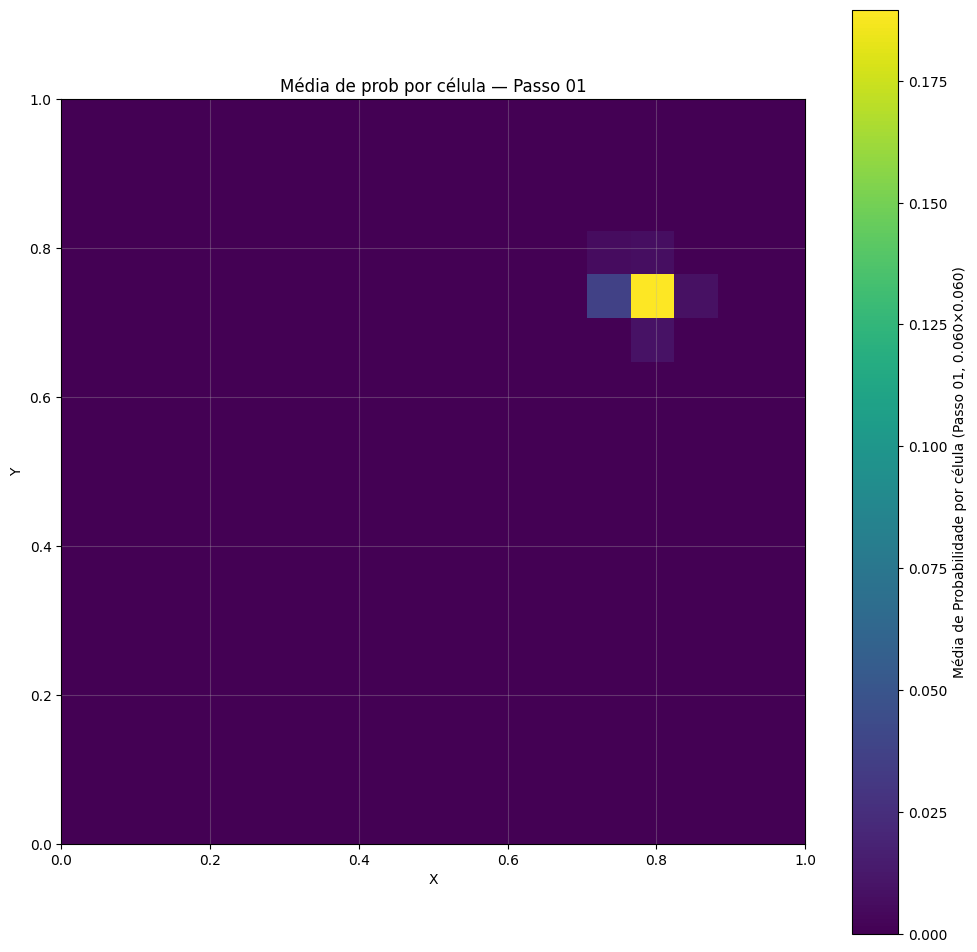

In [33]:
heat, cells = compute_prob_grid_from_apd(
    apd=apd,
    probs_df=distribs_probs,
    passo=0,
    resolucao=0.06,    # grade 0.01 x 0.01
    plot_heat=True,    # mostra o heatmap
)

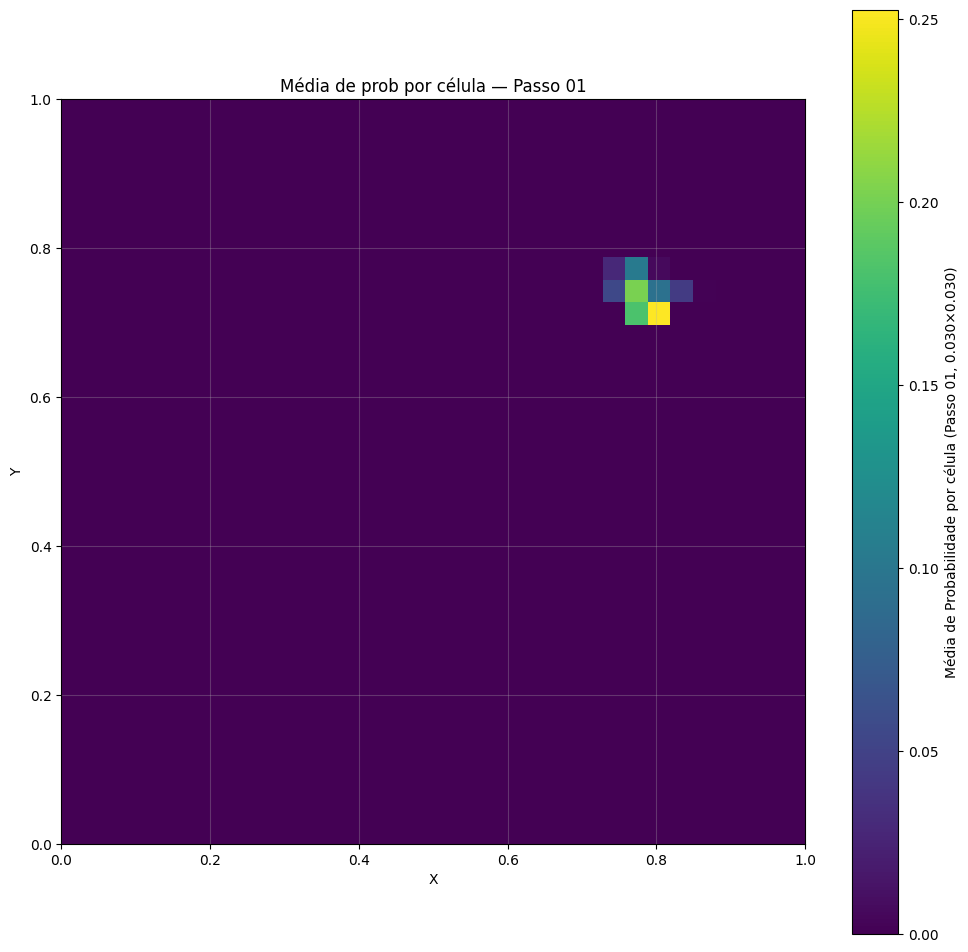

In [34]:
heat, cells = compute_prob_grid_from_apd(
    apd=apd,
    probs_df=distribs_probs,
    passo=0,
    resolucao=0.03,    # grade 0.01 x 0.01
    plot_heat=True,    # mostra o heatmap
)

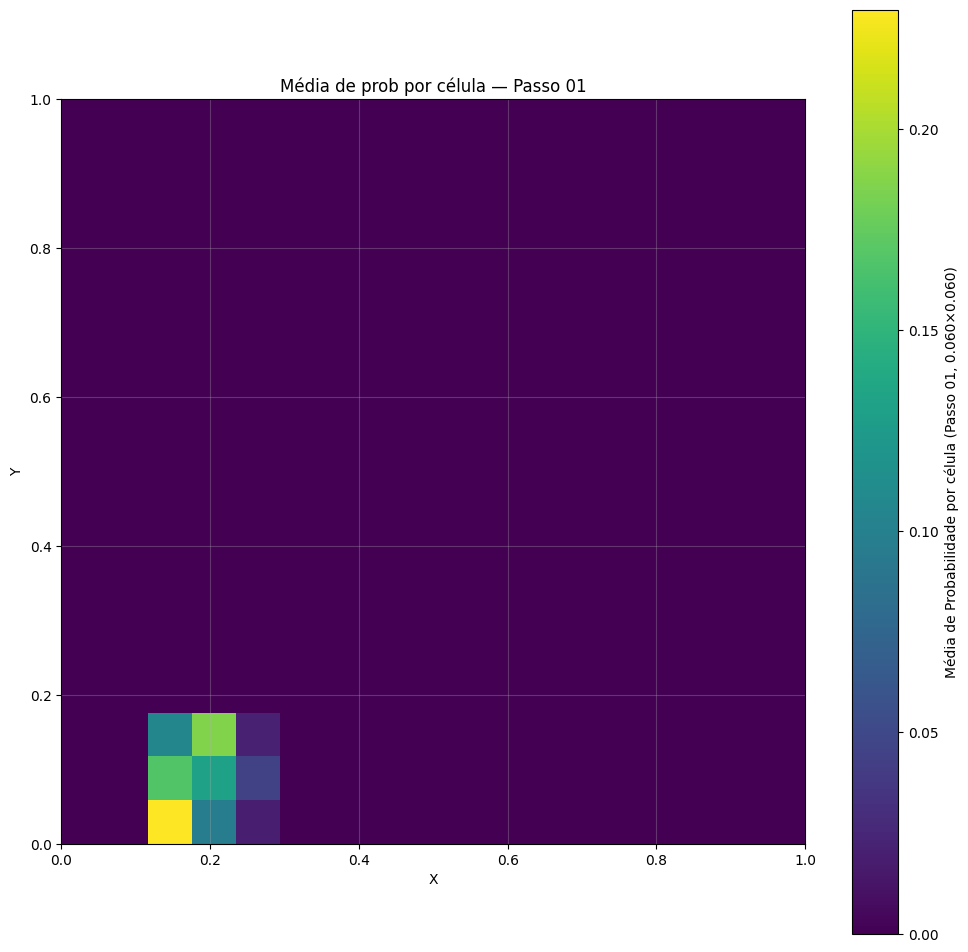

In [69]:
heat, cells = compute_prob_grid_from_apd(
    apd=apd,
    probs_df=distribs_probs705,
    passo=0,
    resolucao=0.06,    # grade 0.01 x 0.01
    plot_heat=True,    # mostra o heatmap
)

In [25]:
# distribs_probs

# FIM